In [2]:
import os
import glob
import numpy as np
import pandas as pd
from pybaselines import whittaker
import matplotlib.pyplot as plt

In [21]:
def normalize_by_value(array, min_value=np.array([]), max_value=np.array([]), axis=1):

    if len(array.shape) == 2:
        if axis != 1:
            array = array.T
            transpose = True
        else:
            transpose = False
        if min_value.size == 0:
            min_value = np.min(array, 1)
        if max_value.size == 0:
            max_value = np.max(array, 1)
        diff = max_value - min_value
        if np.any(diff < 0):
            raise Exception("min_value > max_value")
        norm = (array - min_value[:, np.newaxis]) / diff[:, np.newaxis]

        if transpose:
            norm = norm.T

    elif len(array.shape) == 1:
        if min_value.size == 0:
            min_value = np.min(array)
        if max_value.size == 0:
            max_value = np.max(array)
        diff = max_value - min_value
        if diff < 0:
            raise Exception("min_value > max_value")

        norm = (array - min_value) / (diff)

    return norm


def snv_normalize(spectra, axis=0):
    """
    Standard Normal Variate (SNV) normalization.
    
    Centers each spectrum to zero mean and unit standard deviation.
    Useful for removing multiplicative scatter effects in spectroscopy.
    
    Parameters:
    -----------
    spectra : np.ndarray
        Array of spectra. If 2D, each column (axis=0) or row (axis=1) is a spectrum.
    axis : int
        Axis along which to normalize (0 for column-wise, 1 for row-wise)
    
    Returns:
    --------
    np.ndarray : SNV-normalized spectra
    """
    if len(spectra.shape) == 1:
        # Single spectrum
        mean = np.mean(spectra)
        std = np.std(spectra, ddof=1)
        if std == 0:
            return spectra - mean
        return (spectra - mean) / std
    
    elif len(spectra.shape) == 2:
        # Multiple spectra
        mean = np.mean(spectra, axis=axis, keepdims=True)
        std = np.std(spectra, axis=axis, ddof=1, keepdims=True)
        # Avoid division by zero
        std[std == 0] = 1
        return (spectra - mean) / std
    
    else:
        raise ValueError("Input must be 1D or 2D array")

def baseline_correct(spectrum, wavenumbers, lam=1e3, p=0.0001, niter=100, mode='als', eta=0.0005, show_plot=False):
    """
    Perform baseline correction using pybaselines (Asymmetric Least Squares or drPLS).
    
    Parameters:
    -----------
    spectrum : np.ndarray
        1D array of intensity values corresponding to the spectrum.
    wavenumbers : np.ndarray
        1D array of wavenumber values corresponding to the spectrum.
    lam : float
        Smoothness parameter (default: 1e4). Higher values make the baseline smoother.
    p : float
        Asymmetry parameter for 'als' (default: 0.0001).
    niter : int
        Number of iterations for the algorithm (default: 100).
    mode : str
        Algorithm to use: 'als' or 'drpls' (default: 'als').
    eta : float
        Smoothness parameter for 'drpls' (default: 0.05).
    show_plot : bool
        Whether to plot the results (default: False).
    
    Returns:
    --------
    np.ndarray : Baseline-corrected spectrum
    """
    
    # Ensure 1D to avoid broadcasting issues
    y = np.asanyarray(spectrum).flatten()
    
    if mode == 'als':
        # Asymmetric Least Squares
        baseline, _ = whittaker.asls(y, lam=lam, p=p, max_iter=niter)
    elif mode == 'drpls':
        # Dually Reweighted Penalized Least Squares
        baseline, _ = whittaker.drpls(y, lam=lam, eta=eta, max_iter=niter)
    else:
        raise ValueError(f"Unknown mode: {mode}. Use 'als' or 'drpls'.")

    corrected_spectrum = y - baseline

    if show_plot:
        plt.figure(figsize=(10, 4))
        plt.plot(wavenumbers, y, label='Original Spectrum', color='blue')    
        plt.plot(wavenumbers, baseline, label='Estimated Baseline', color='red', linestyle='--')
        plt.plot(wavenumbers, corrected_spectrum, label='Baseline-Corrected Spectrum', color='green')
        plt.title(f'Baseline Correction ({mode.upper()})')
        plt.legend()
        plt.show()

    return corrected_spectrum

def load_txt_folder_to_array(
    folder_dir,
    skip_first_column=True,
    remove_spectra=[],
    baseline_correction=True,
    show_plot=False
):
    """
    Load .txt files for a condition into a dictionary with individual spectra
    and average/std summary curves. Supports a single folder path or list of folders.
    """
    if isinstance(folder_dir, (list, tuple)):
        files = []
        for d in folder_dir:
            files.extend(glob.glob(os.path.join(d, '*.txt')))
        files = sorted(files)
    else:
        files = sorted(glob.glob(os.path.join(folder_dir, '*.txt')))

    if not files:
        raise FileNotFoundError(f"No .txt files found in: {folder_dir}")

    first_data = np.loadtxt(files[0])
    ref_wavenumbers = first_data[:, 0]

    spectra_list = []
    filenames_list = []
    file_dict = {}

    for idx, file_path in enumerate(files):
        filename = os.path.basename(file_path)

        if idx in remove_spectra or filename in remove_spectra:
            continue

        temp = first_data if idx == 0 else np.loadtxt(file_path)
        file_wavenumbers = temp[:, 0]
        file_spec = temp[:, 1:]

        # Interpolate if wavenumber grid differs
        if file_wavenumbers.shape[0] != ref_wavenumbers.shape[0] or not np.array_equal(file_wavenumbers, ref_wavenumbers):
            if file_spec.shape[1] == 1:
                interp_spec = np.interp(ref_wavenumbers, file_wavenumbers, file_spec.flatten())
                file_spec = interp_spec[:, np.newaxis]
            else:
                file_spec = np.column_stack([
                    np.interp(ref_wavenumbers, file_wavenumbers, file_spec[:, col])
                    for col in range(file_spec.shape[1])
                ])

        # Baseline correction
        if baseline_correction is not None and baseline_correction is not False:
            mode = baseline_correction if isinstance(baseline_correction, str) else 'als'
            if callable(baseline_correction):
                corrected = baseline_correction(file_spec, ref_wavenumbers)
            elif file_spec.shape[1] == 1:
                corrected = baseline_correct(file_spec.flatten(), ref_wavenumbers, mode=mode, show_plot=show_plot)
            else:
                corrected = np.column_stack([
                    baseline_correct(file_spec[:, col], ref_wavenumbers, mode=mode, show_plot=show_plot)
                    for col in range(file_spec.shape[1])
                ])
        else:
            corrected = file_spec

        corrected = corrected.squeeze()
        if corrected.ndim == 1:
            spectra_list.append(corrected)
            filenames_list.append(filename)
            file_dict[filename] = corrected
        else:
            for col in range(corrected.shape[1]):
                col_name = f"{filename}_col{col+1}"
                spectra_list.append(corrected[:, col])
                filenames_list.append(col_name)
                file_dict[col_name] = corrected[:, col]

    spectra_matrix = np.column_stack(spectra_list)
    mean_spectrum = np.mean(spectra_matrix, axis=1)
    median_spectrum = np.median(spectra_matrix, axis=1)
    std_spectrum = np.std(spectra_matrix, axis=1, ddof=1) if spectra_matrix.shape[1] > 1 else np.zeros_like(mean_spectrum)

    out = {
        'wavenumbers': ref_wavenumbers,
        'filenames': filenames_list,
        'spectra': spectra_matrix,
        'mean': mean_spectrum,
        'median': median_spectrum,
        'std': std_spectrum,
        'combined_array': np.column_stack([ref_wavenumbers, spectra_matrix]),
    }
    # Direct access by filename: out['sample_01.txt']
    out.update(file_dict)
    return out



def crop_and_normalize_region(base_directory, txt_arr, start_wavenumber, end_wavenumber, 
                              region_name="Region", plot=False, 
                              peak_labels=None, normalization='minmax'):
    """
    Crop and normalize spectra for a specific wavenumber region.
    
    Parameters:
    -----------
    base_directory : dir (str)
        Directory path for output
    txt_arr : np.ndarray
        Array with wavenumbers in first column and spectra in subsequent columns
    start_wavenumber : float
        Starting wavenumber for the region
    end_wavenumber : float
        Ending wavenumber for the region
    region_name : str
        Name of the region (e.g., "CH Stretching", "Fingerprint", "CD")
    plot : bool
        Whether to plot the normalized spectra
    peak_labels : dict
        Dictionary mapping wavenumber values (float or str) to peak labels
        Example: {2930: 'CH3', 2850: 'CH2', '1655': 'Amide I'}
    normalization : str
        Type of normalization: 'minmax' (default) or 'snv' (Standard Normal Variate)
    
    Returns:
    --------
    dict : Dictionary containing:
        - 'wavenumbers': wavenumber array for the region
        - 'normalized_spectra': normalized spectra array
        - 'cropped_array': original cropped array (wavenumbers + spectra)
    """
    # Find indices for cropping
    first_idx = np.argmin(np.abs(txt_arr[:, 0] - start_wavenumber))
    last_idx = np.argmin(np.abs(txt_arr[:, 0] - end_wavenumber))
    
    # Ensure proper ordering
    if first_idx > last_idx:
        first_idx, last_idx = last_idx, first_idx
    
    # Crop the array
    cropped_arr = txt_arr[first_idx:last_idx, :]
    wavenumbers = cropped_arr[:, 0]
    
    # Normalize spectra
    if normalization == 'snv':
        norm_arr_crop = snv_normalize(cropped_arr[:, 1:], axis=0)
    else:  # default to minmax
        norm_arr_crop = normalize_by_value(cropped_arr[:, 1:], axis=0)
    
    # Plot if requested
    if plot:
        plt.figure(figsize=(10, 6))
        for idx, arr in enumerate(norm_arr_crop.T):
            plt.plot(wavenumbers, arr, label=f'Spectra {idx+1}')
        
        # Get current y-axis limits
        y_min, y_max = plt.ylim()
        y_range = y_max - y_min
        
        # Add peak labels if provided
        if peak_labels:
            max_label_height = 0
            for wavenumber, label in peak_labels.items():
                wn = float(wavenumber)
                # Find closest wavenumber in the region
                if start_wavenumber <= wn <= end_wavenumber or end_wavenumber <= wn <= start_wavenumber:
                    wn_idx = np.argmin(np.abs(wavenumbers - wn))
                    # Get max intensity at this wavenumber
                    max_intensity = np.max(norm_arr_crop[wn_idx, :])
                    max_label_height = max(max_label_height, max_intensity)
                    
                    plt.axvline(x=wn, color='gray', linestyle='--', alpha=0.5, zorder=1)
            
            # Extend y-axis if labels would be too close to the top
            # Reserve 20% of the plot height for labels
            if max_label_height > y_max - 0.2 * y_range:
                new_y_max = max_label_height + 0.4 * y_range
                plt.ylim(y_min, new_y_max)
                y_max = new_y_max
                y_range = y_max - y_min
            
            # Now add text labels with updated margins
            for wavenumber, label in peak_labels.items():
                wn = float(wavenumber)
                if start_wavenumber <= wn <= end_wavenumber or end_wavenumber <= wn <= start_wavenumber:
                    wn_idx = np.argmin(np.abs(wavenumbers - wn))
                    max_intensity = np.max(norm_arr_crop[wn_idx, :])
                    # Position text above the highest peak with padding
                    text_y = max_intensity + 0.05 * y_range
                    
                    plt.text(wn, text_y, label, 
                            rotation=90, verticalalignment='bottom', horizontalalignment='center',
                            fontsize=11, fontweight='bold', alpha=1.0,
                            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', 
                                     edgecolor='gray', alpha=0.9, linewidth=0.5),
                            zorder=5, clip_on=True)
        
        plt.xlabel('Wavenumber (cm$^{-1}$)')
        plt.ylabel('Normalized Intensity (A.U.)')
        plt.title(f"{region_name}")
        plt.legend().set_visible(True)
        plt.tight_layout()
        
        # Save figure to base directory
        safe_filename = region_name.replace(' ', '_').replace('/', '_').replace('\\', '_') + '.png'
        save_path = os.path.join(base_directory, "images", safe_filename)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved: {save_path}")
        
        plt.show()
    
    return {
        'wavenumbers': wavenumbers,
        'normalized_spectra': norm_arr_crop,
        'cropped_array': cropped_arr
    }



def crop_and_normalize_region(
    data, 
    start_wavenumber, 
    end_wavenumber, 
    region_name="Region", 
    plot=False, 
    peak_labels=None, 
    normalization='minmax',
    show_std=True,
    plot_individual=False,
    save_dir=None
):
    """
    Crop and normalize spectra for a specific wavenumber region.
    Supports either a single condition (2D array or dict) or multiple conditions (dict of dicts/arrays).
    """
    # Detect if data is a multi-condition dict or a single condition
    is_multi_condition = (
        isinstance(data, dict) and 
        'wavenumbers' not in data and 
        all(isinstance(v, (dict, np.ndarray)) for v in data.values())
    )

    condition_dict = data if is_multi_condition else {"Condition": data}
    processed_conditions = {}
    ref_cropped_wn = None

    for cond_name, cond_val in condition_dict.items():
        if isinstance(cond_val, dict):
            wn = cond_val['wavenumbers']
            spec = cond_val['spectra']
            fnames = cond_val.get('filenames', [f"Spec_{i+1}" for i in range(spec.shape[1])])
        else:
            wn = cond_val[:, 0]
            spec = cond_val[:, 1:]
            fnames = [f"Spec_{i+1}" for i in range(spec.shape[1])]

        first_idx = np.argmin(np.abs(wn - start_wavenumber))
        last_idx = np.argmin(np.abs(wn - end_wavenumber))
        if first_idx > last_idx:
            first_idx, last_idx = last_idx, first_idx

        cropped_wn = wn[first_idx:last_idx]
        cropped_spec = spec[first_idx:last_idx, :]

        if ref_cropped_wn is None:
            ref_cropped_wn = cropped_wn

        # Normalize in region
        if normalization == 'snv':
            norm_spec = snv_normalize(cropped_spec, axis=0)
        else:
            norm_spec = normalize_by_value(cropped_spec, axis=0)

        mean_spec = np.mean(norm_spec, axis=1)
        median_spec = np.median(norm_spec, axis=1)
        std_spec = np.std(norm_spec, axis=1, ddof=1) if norm_spec.shape[1] > 1 else np.zeros_like(mean_spec)

        processed_conditions[cond_name] = {
            'wavenumbers': cropped_wn,
            'normalized_spectra': norm_spec,
            'mean': mean_spec,
            'median': median_spec,
            'std': std_spec,
            'filenames': fnames
        }

    if plot:
        fig, ax = plt.subplots(figsize=(10, 6))
        palette = ['#1f77b4', '#d62728', '#2ca02c', '#9467bd', '#ff7f0e', '#8c564b', '#e377c2']
        all_max_heights = []

        for c_idx, (cond_name, c_data) in enumerate(processed_conditions.items()):
            color = palette[c_idx % len(palette)]
            wn = c_data['wavenumbers']
            norm_spec = c_data['normalized_spectra']
            mean_spec = c_data['mean']
            std_spec = c_data['std']
            n_samples = norm_spec.shape[1]

            if not is_multi_condition:
                for s_idx in range(n_samples):
                    label = fnames[s_idx] if s_idx < len(fnames) else f'Spectra {s_idx+1}'
                    ax.plot(wn, norm_spec[:, s_idx], label=label, alpha=0.7)
                all_max_heights.append(np.max(norm_spec))
            else:
                if plot_individual:
                    for s_idx in range(n_samples):
                        ax.plot(wn, norm_spec[:, s_idx], color=color, alpha=0.2, linewidth=0.8)

                ax.plot(wn, mean_spec, color=color, linewidth=2.2, label=f"{cond_name} (n={n_samples})")

                if show_std and n_samples > 1:
                    ax.fill_between(wn, mean_spec - std_spec, mean_spec + std_spec, color=color, alpha=0.2)
                    all_max_heights.append(np.max(mean_spec + std_spec))
                else:
                    all_max_heights.append(np.max(mean_spec))

        # Peak Labels positioned above all conditions
        if peak_labels and len(all_max_heights) > 0:
            y_min, y_max = ax.get_ylim()
            y_range = y_max - y_min
            max_label_height = 0

            for wavenumber, label in peak_labels.items():
                w_val = float(wavenumber)
                min_w = min(start_wavenumber, end_wavenumber)
                max_w = max(start_wavenumber, end_wavenumber)
                if min_w <= w_val <= max_w:
                    wn_idx = np.argmin(np.abs(ref_cropped_wn - w_val))
                    local_max = max(c['mean'][wn_idx] + (c['std'][wn_idx] if show_std else 0) for c in processed_conditions.values())
                    max_label_height = max(max_label_height, local_max)
                    ax.axvline(x=w_val, color='gray', linestyle='--', alpha=0.5, zorder=1)

            if max_label_height > y_max - 0.2 * y_range:
                new_y_max = max_label_height + 0.4 * y_range
                ax.set_ylim(y_min, new_y_max)
                y_max = new_y_max
                y_range = y_max - y_min

            for wavenumber, label in peak_labels.items():
                w_val = float(wavenumber)
                min_w = min(start_wavenumber, end_wavenumber)
                max_w = max(start_wavenumber, end_wavenumber)
                if min_w <= w_val <= max_w:
                    wn_idx = np.argmin(np.abs(ref_cropped_wn - w_val))
                    local_max = max(c['mean'][wn_idx] + (c['std'][wn_idx] if show_std else 0) for c in processed_conditions.values())
                    text_y = local_max + 0.05 * y_range
                    ax.text(
                        w_val, text_y, label,
                        rotation=90, verticalalignment='bottom', horizontalalignment='center',
                        fontsize=10, fontweight='bold', alpha=0.9,
                        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='gray', alpha=0.9, linewidth=0.5),
                        zorder=5, clip_on=True
                    )

        ax.set_xlabel(r'Wavenumber (cm$^{-1}$)', fontsize=12, fontweight='bold')
        ax.set_ylabel(f'Normalized Intensity ({normalization.capitalize()})', fontsize=12, fontweight='bold')
        ax.set_title(f"{region_name}", fontsize=14, fontweight='bold')
        ax.legend(loc='best')
        plt.tight_layout()

        if save_dir:
            os.makedirs(save_dir, exist_ok=True)
            safe_filename = region_name.replace(' ', '_').replace('/', '_').replace('\\', '_') + '.png'
            save_path = os.path.join(save_dir, safe_filename)
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
            print(f"Saved: {save_path}")

        plt.show()

    if not is_multi_condition:
        c_first = list(processed_conditions.values())[0]
        return {
            'wavenumbers': c_first['wavenumbers'],
            'normalized_spectra': c_first['normalized_spectra'],
            'cropped_array': np.column_stack([c_first['wavenumbers'], c_first['normalized_spectra']]),
            'mean': c_first['mean'],
            'std': c_first['std']
        }
    else:
        return {
            'wavenumbers': ref_cropped_wn,
            'conditions': processed_conditions
        }


Loading Day 4...
Loading Day 5...


Loading Day 4...
Loading Day 5...
Saved: E:\Embryo Day 4 vs Day 5\images\Embryo_Day_4_vs_Day_5_-_CH_Stretching.png


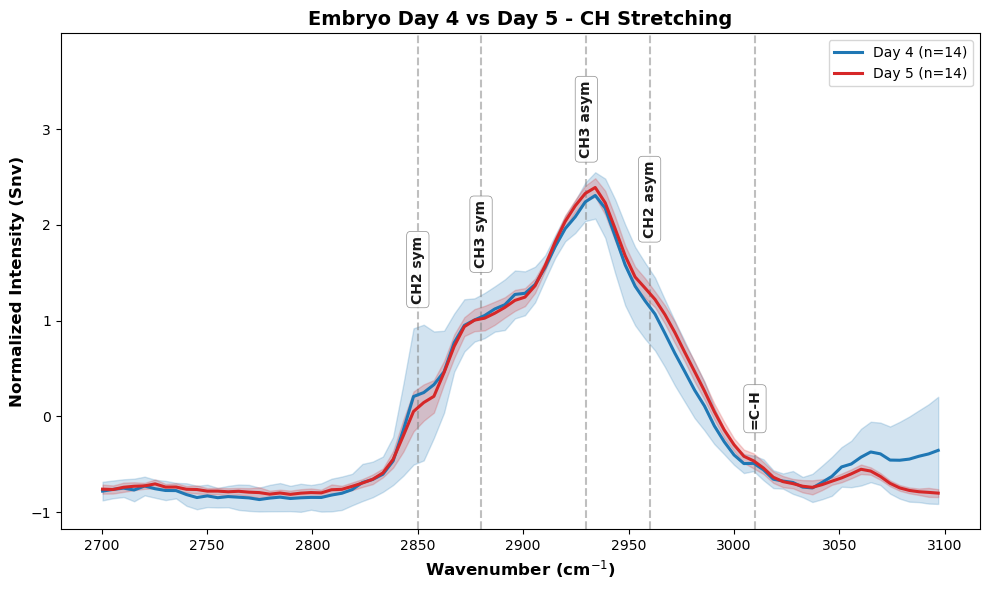

Saved: E:\Embryo Day 4 vs Day 5\images\Embryo_Day_4_vs_Day_5_-_Fingerprint.png


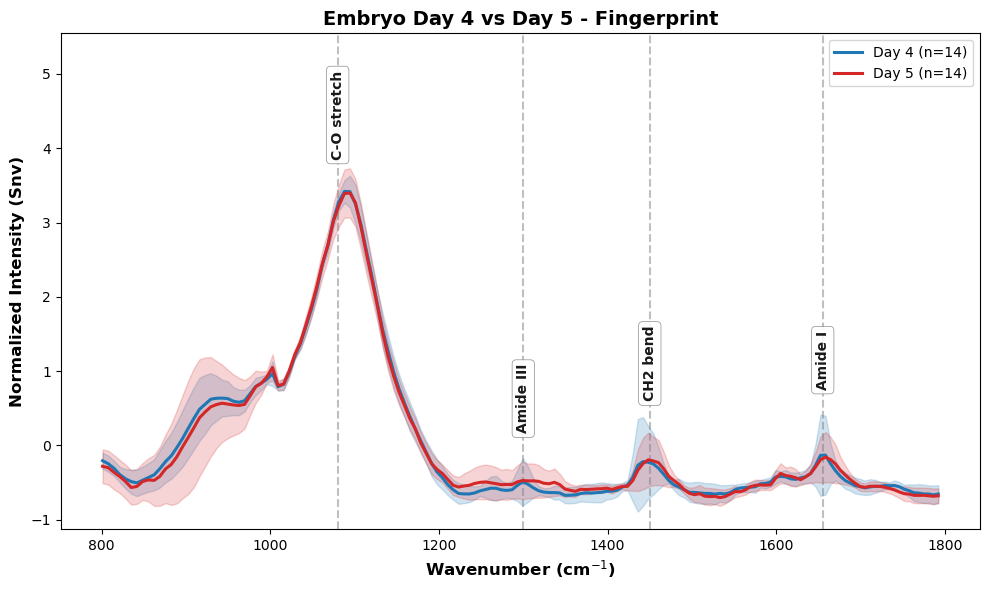

Saved: E:\Embryo Day 4 vs Day 5\images\Embryo_Day_4_vs_Day_5_-_CD.png


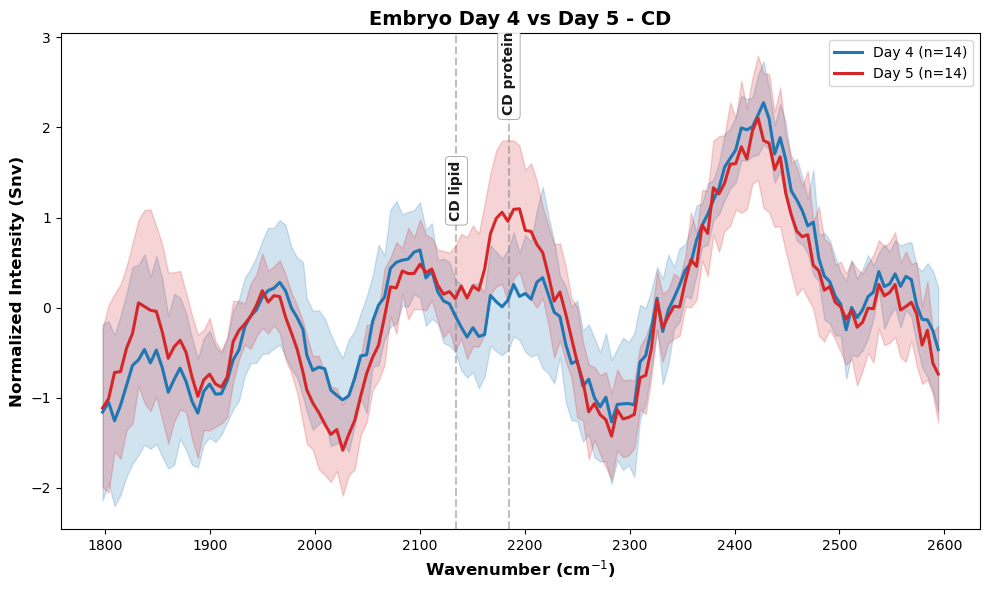

{'wavenumbers': array([1797.66, 1803.38, 1809.1 , 1814.82, 1820.52, 1826.22, 1831.91,
        1837.59, 1843.27, 1848.94, 1854.61, 1860.27, 1865.92, 1871.57,
        1877.2 , 1882.84, 1888.46, 1894.08, 1899.7 , 1905.3 , 1910.9 ,
        1916.5 , 1922.09, 1927.67, 1933.24, 1938.81, 1944.37, 1949.92,
        1955.47, 1961.01, 1966.55, 1972.08, 1977.6 , 1983.12, 1988.63,
        1992.32, 1998.05, 2003.77, 2009.49, 2015.21, 2020.91, 2026.62,
        2032.31, 2038.  , 2043.69, 2049.37, 2055.04, 2060.71, 2066.37,
        2072.03, 2077.68, 2083.33, 2088.97, 2094.6 , 2100.23, 2105.85,
        2111.47, 2117.08, 2122.69, 2128.29, 2133.89, 2139.47, 2145.06,
        2150.64, 2156.21, 2161.78, 2167.34, 2172.89, 2178.44, 2183.99,
        2189.52, 2195.06, 2200.58, 2206.11, 2211.62, 2217.13, 2222.64,
        2228.13, 2233.63, 2239.12, 2244.6 , 2250.08, 2255.55, 2261.02,
        2266.47, 2271.93, 2277.38, 2282.82, 2288.26, 2293.69, 2299.12,
        2304.54, 2309.95, 2315.36, 2320.77, 2326.17, 2331.56, 

In [60]:
conditions_folders = {
    "Day 4": [
        r"E:\11-07-25 Embryo 10 Day 4",
        r"E:\11-07-25 Embryo 11 Day 4",
    ],
    "Day 5": [
        r"E:\11-11-25 Embryo 14 Day 5",
        r"E:\11-11-25 Embryo 16 Day 5",
    ],
}
output_images_dir = r"E:\Embryo Day 4 vs Day 5\images"

conditions_data = {}
for cond_name, folder_paths in conditions_folders.items():
    print(f"Loading {cond_name}...")
    conditions_data[cond_name] = load_txt_folder_to_array(folder_paths, baseline_correction=True)

# Choose normalization method: 'minmax' or 'snv'
full_spectrum_normalization = 'snv'  # Change to 'minmax' for min-max normalization

# Define peak labels for different regions
ch_peaks = {
    2850: 'CH2 sym',
    2880: 'CH3 sym', 
    2930: 'CH3 asym',
    2960: 'CH2 asym',
    3010: '=C-H'
}

fingerprint_peaks = {
    1655: 'Amide I',
    1450: 'CH2 bend',
    1300: 'Amide III',
    1080: 'C-O stretch'
}

cd_peaks = {
    2135: 'CD lipid',
    2185: 'CD protein'
}

# Compare conditions in the CH Stretching region
crop_and_normalize_region(
    conditions_data,
    start_wavenumber=2700,
    end_wavenumber=3100,
    region_name="Embryo Day 4 vs Day 5 - CH Stretching",
    plot=True,
    peak_labels=ch_peaks,
    normalization='snv',
    show_std=True,          # Shaded +/- 1 SD band
    plot_individual=False,  # Set to True to also show faint individual lines
    save_dir=output_images_dir
)
# Compare conditions in the Fingerprint region
crop_and_normalize_region(
    conditions_data,
    start_wavenumber=800,
    end_wavenumber=1800,
    region_name="Embryo Day 4 vs Day 5 - Fingerprint",
    plot=True,
    peak_labels=fingerprint_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)
# Compare conditions in the Fingerprint region
crop_and_normalize_region(
    conditions_data,
    start_wavenumber=1800,
    end_wavenumber=2600,
    region_name="Embryo Day 4 vs Day 5 - CD",
    plot=True,
    peak_labels=cd_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)


Saved: E:\Embryo Day 4 vs Day 5\images\Day_4_CH_Stretching.png


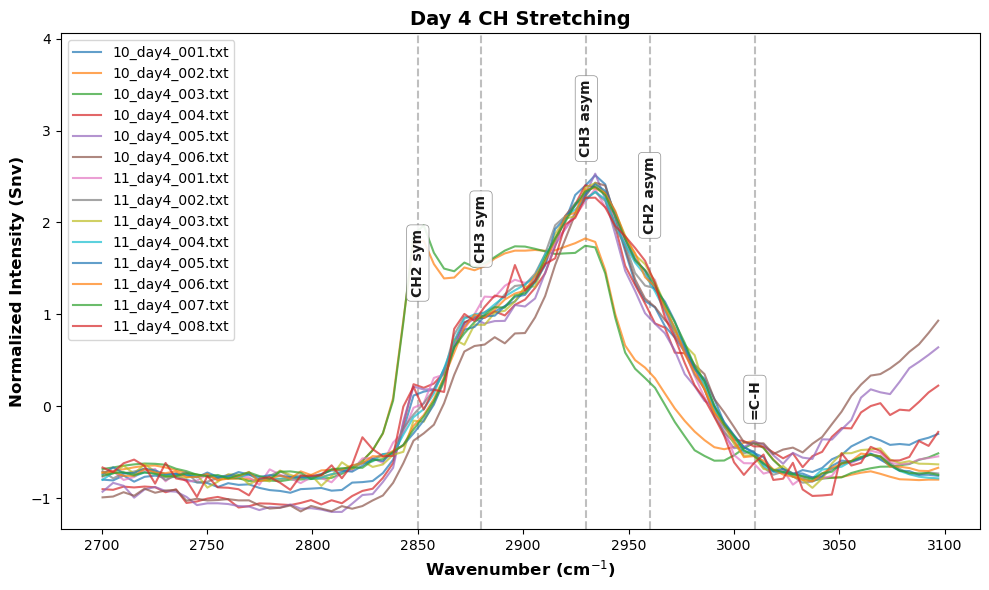

Saved: E:\Embryo Day 4 vs Day 5\images\Day_4_Fingerprint.png


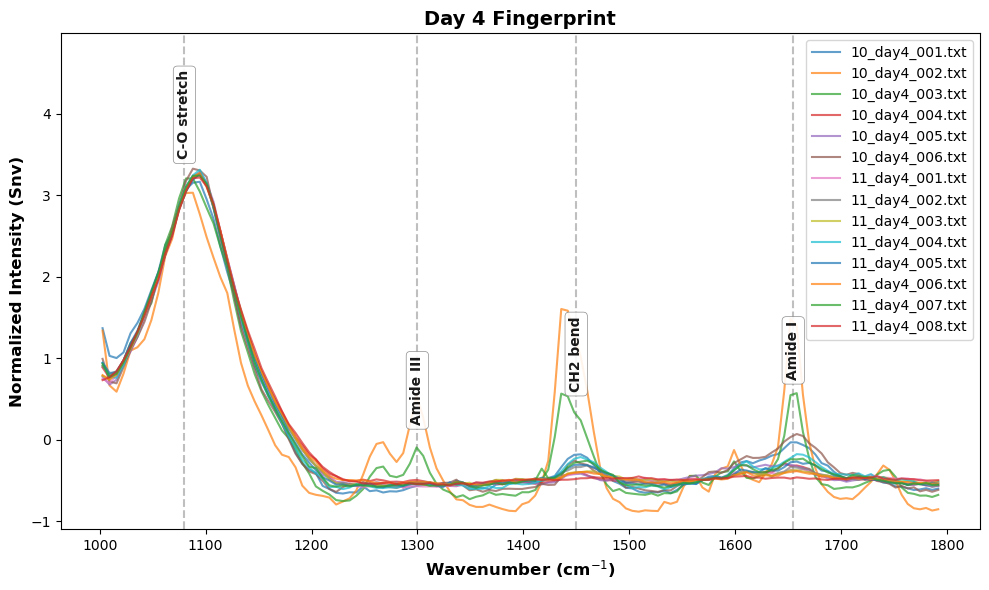

Saved: E:\Embryo Day 4 vs Day 5\images\Day_4_CD.png


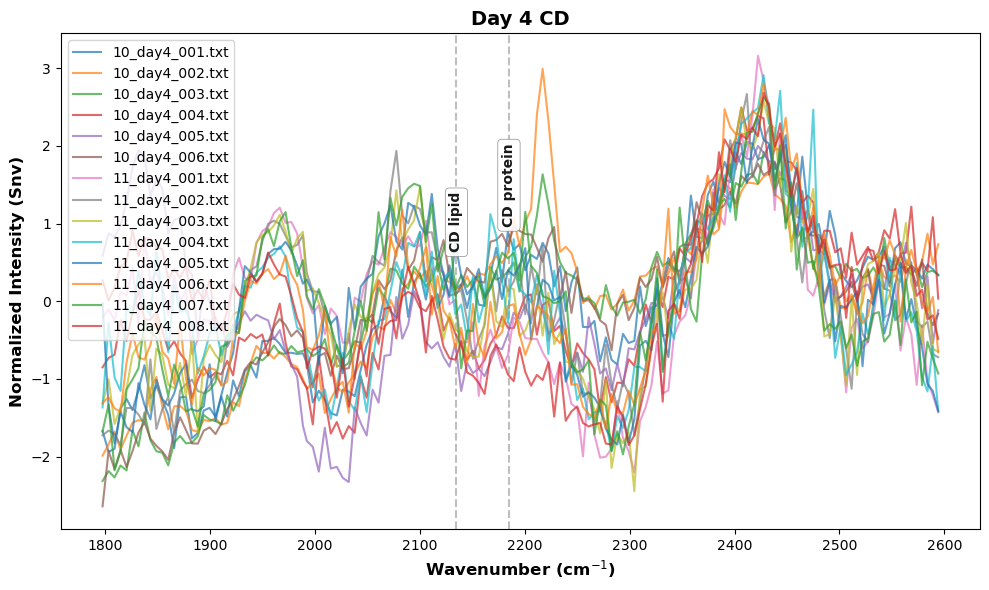

{'wavenumbers': array([1797.66, 1803.38, 1809.1 , 1814.82, 1820.52, 1826.22, 1831.91,
        1837.59, 1843.27, 1848.94, 1854.61, 1860.27, 1865.92, 1871.57,
        1877.2 , 1882.84, 1888.46, 1894.08, 1899.7 , 1905.3 , 1910.9 ,
        1916.5 , 1922.09, 1927.67, 1933.24, 1938.81, 1944.37, 1949.92,
        1955.47, 1961.01, 1966.55, 1972.08, 1977.6 , 1983.12, 1988.63,
        1992.32, 1998.05, 2003.77, 2009.49, 2015.21, 2020.91, 2026.62,
        2032.31, 2038.  , 2043.69, 2049.37, 2055.04, 2060.71, 2066.37,
        2072.03, 2077.68, 2083.33, 2088.97, 2094.6 , 2100.23, 2105.85,
        2111.47, 2117.08, 2122.69, 2128.29, 2133.89, 2139.47, 2145.06,
        2150.64, 2156.21, 2161.78, 2167.34, 2172.89, 2178.44, 2183.99,
        2189.52, 2195.06, 2200.58, 2206.11, 2211.62, 2217.13, 2222.64,
        2228.13, 2233.63, 2239.12, 2244.6 , 2250.08, 2255.55, 2261.02,
        2266.47, 2271.93, 2277.38, 2282.82, 2288.26, 2293.69, 2299.12,
        2304.54, 2309.95, 2315.36, 2320.77, 2326.17, 2331.56, 

In [61]:
crop_and_normalize_region(
    conditions_data['Day 4'],
    start_wavenumber=2700,
    end_wavenumber=3100,
    region_name="Day 4 CH Stretching",
    plot=True,
    peak_labels=ch_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)

# Compare conditions in the Fingerprint region
crop_and_normalize_region(
    conditions_data['Day 4'],
    start_wavenumber=1000,
    end_wavenumber=1800,
    region_name="Day 4 Fingerprint",
    plot=True,
    peak_labels=fingerprint_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)
# Compare conditions in the Fingerprint region
crop_and_normalize_region(
    conditions_data['Day 4'],
    start_wavenumber=1800,
    end_wavenumber=2600,
    region_name="Day 4 CD",
    plot=True,
    peak_labels=cd_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)

Saved ratio plot: E:\Embryo Day 4 vs Day 5\images\lip_pro_ratio.png


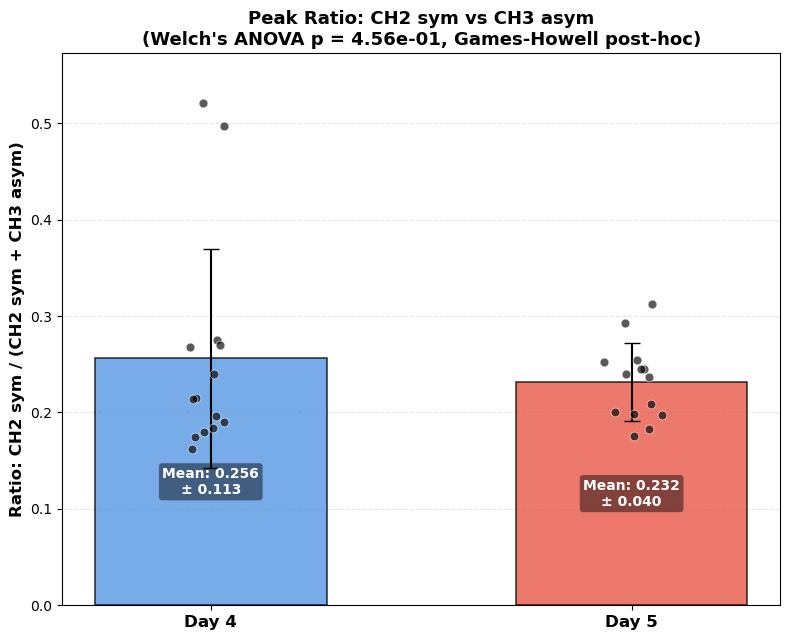

   Condition         Filename     Ratio
0      Day 4  10_day4_001.txt  0.240175
1      Day 4  10_day4_002.txt  0.497724
2      Day 4  10_day4_003.txt  0.520736
3      Day 4  10_day4_004.txt  0.275347
4      Day 4  10_day4_005.txt  0.269568
5      Day 4  10_day4_006.txt  0.190441
6      Day 4  11_day4_001.txt  0.215349
7      Day 4  11_day4_002.txt  0.213778
8      Day 4  11_day4_003.txt  0.179708
9      Day 4  11_day4_004.txt  0.196160
10     Day 4  11_day4_005.txt  0.162041
11     Day 4  11_day4_006.txt  0.183568
12     Day 4  11_day4_007.txt  0.175013
13     Day 4  11_day4_008.txt  0.267678
14     Day 5  14_day5_001.txt  0.200765
15     Day 5  14_day5_002.txt  0.244977
16     Day 5  14_day5_003.txt  0.183342
17     Day 5  14_day5_004.txt  0.251978
18     Day 5  14_day5_005.txt  0.208633
19     Day 5  14_day5_006.txt  0.293218
20     Day 5  14_day5_007.txt  0.237145
21     Day 5  14_day5_008.txt  0.245380
22     Day 5  16_day5_001.txt  0.197233
23     Day 5  16_day5_002.txt  0.198033


In [69]:
# 1. Define peak labels
ch_peaks = {
    2850: 'CH2 sym',
    2880: 'CH3 sym',
    2930: 'CH3 asym',
    2960: 'CH2 asym',
    3010: '=C-H'
}

# 2. Compute ratio: e.g. CH2 / (CH2 + CH3) using either wavenumbers or labels
ratio_df, ratio_summary, aov_table, posthoc_table = calculate_peak_ratio(
    conditions_data,          # {"Day 4": day4_data, "Day 5": day5_data}
    peak_a='CH2 sym',         # or 2850
    peak_b='CH3 asym',        # or 2930
    peak_labels=ch_peaks,
    window=5,                 # searches +/- 5 cm^-1 around peak
    plot=True,
    show_ns=False,            # Only display significant comparison brackets (*, **, ***)
    save_path=r"E:\Embryo Day 4 vs Day 5\images\lip_pro_ratio.png"
)

# 3. View individual data points & summary
print(ratio_df[['Condition', 'Filename', 'Ratio']])
print(ratio_summary)

# 4. Save table to CSV
ratio_df.to_csv(r"E:\Embryo Day 4 vs Day 5\images\peak_ratios.csv", index=False)


# Statistical tables:
print("Welch's ANOVA Table:")
print(aov_table)
print("\nGames-Howell Post-hoc Comparisons:")
print(posthoc_table[['A', 'B', 'diff', 'pval']])


Saved ratio plot: E:\Embryo Day 4 vs Day 5\images\unsat_ratio.png


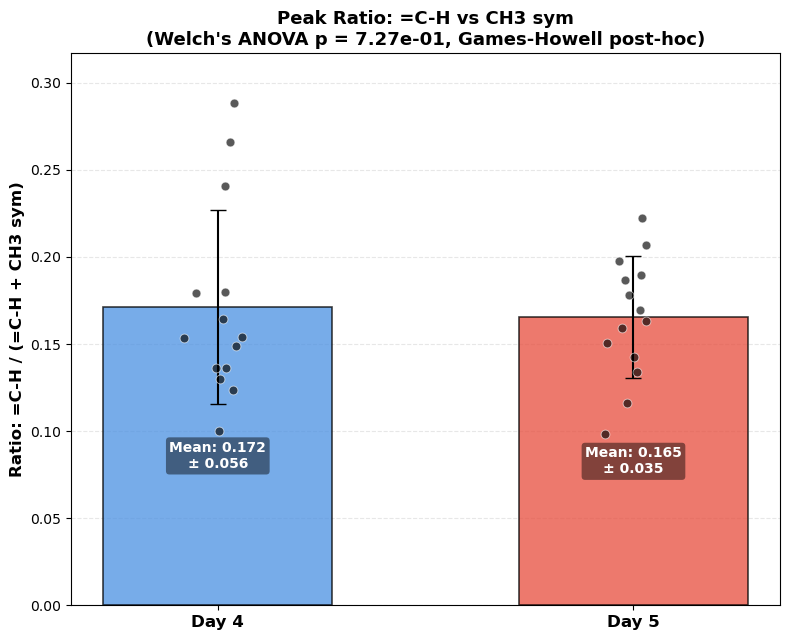

   Condition         Filename     Ratio
0      Day 4  10_day4_001.txt  0.179925
1      Day 4  10_day4_002.txt  0.153675
2      Day 4  10_day4_003.txt  0.148660
3      Day 4  10_day4_004.txt  0.240963
4      Day 4  10_day4_005.txt  0.266051
5      Day 4  10_day4_006.txt  0.288231
6      Day 4  11_day4_001.txt  0.100320
7      Day 4  11_day4_002.txt  0.153975
8      Day 4  11_day4_003.txt  0.164492
9      Day 4  11_day4_004.txt  0.136496
10     Day 4  11_day4_005.txt  0.136172
11     Day 4  11_day4_006.txt  0.129824
12     Day 4  11_day4_007.txt  0.123584
13     Day 4  11_day4_008.txt  0.179078
14     Day 5  14_day5_001.txt  0.150503
15     Day 5  14_day5_002.txt  0.142743
16     Day 5  14_day5_003.txt  0.178095
17     Day 5  14_day5_004.txt  0.116167
18     Day 5  14_day5_005.txt  0.098173
19     Day 5  14_day5_006.txt  0.133968
20     Day 5  14_day5_007.txt  0.169544
21     Day 5  14_day5_008.txt  0.159368
22     Day 5  16_day5_001.txt  0.222367
23     Day 5  16_day5_002.txt  0.197531


In [71]:
# 2. Compute ratio: e.g. CH2 / (CH2 + CH3) using either wavenumbers or labels
ratio_df, ratio_summary, aov_table, posthoc_table = calculate_peak_ratio(
    conditions_data,          # {"Day 4": day4_data, "Day 5": day5_data}
    peak_a='=C-H',         # or 2850
    peak_b='CH3 sym',        # or 2930
    peak_labels=ch_peaks,
    window=5,                 # searches +/- 5 cm^-1 around peak
    plot=True,
        show_ns=False,            # Only display significant comparison brackets (*, **, ***)
    save_path=r"E:\Embryo Day 4 vs Day 5\images\unsat_ratio.png"
)

# 3. View individual data points & summary
print(ratio_df[['Condition', 'Filename', 'Ratio']])
print(ratio_summary)

# 4. Save table to CSV
ratio_df.to_csv(r"E:\Embryo Day 4 vs Day 5\images\peak_ratios.csv", index=False)

Saved ratio plot: E:\Embryo Day 4 vs Day 5\images\cd_lipid_ratio.png


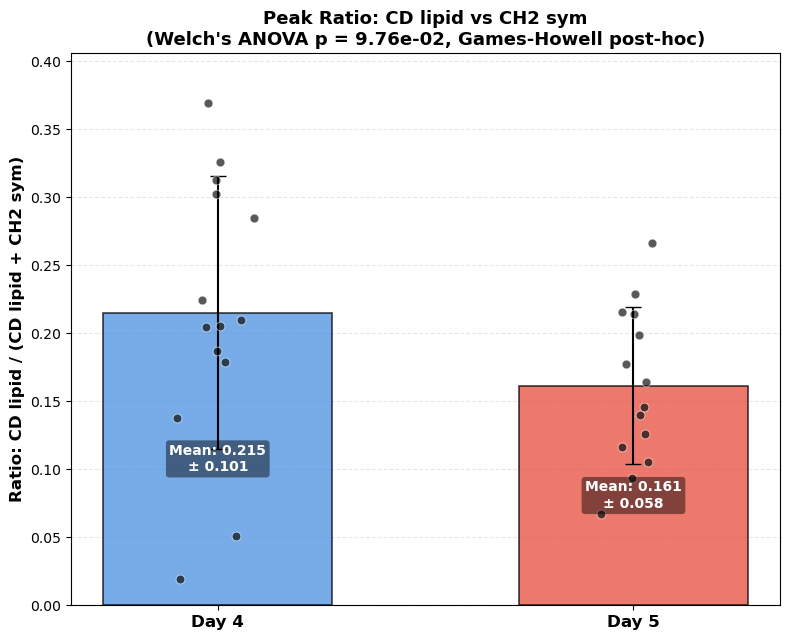

   Condition         Filename     Ratio
0      Day 4  10_day4_001.txt  0.186669
1      Day 4  10_day4_002.txt  0.019387
2      Day 4  10_day4_003.txt  0.050856
3      Day 4  10_day4_004.txt  0.137950
4      Day 4  10_day4_005.txt  0.205187
5      Day 4  10_day4_006.txt  0.284815
6      Day 4  11_day4_001.txt  0.312820
7      Day 4  11_day4_002.txt  0.224070
8      Day 4  11_day4_003.txt  0.326115
9      Day 4  11_day4_004.txt  0.178837
10     Day 4  11_day4_005.txt  0.302548
11     Day 4  11_day4_006.txt  0.204460
12     Day 4  11_day4_007.txt  0.209480
13     Day 4  11_day4_008.txt  0.368902
14     Day 5  14_day5_001.txt  0.228889
15     Day 5  14_day5_002.txt  0.163866
16     Day 5  14_day5_003.txt  0.266168
17     Day 5  14_day5_004.txt  0.198479
18     Day 5  14_day5_005.txt  0.214015
19     Day 5  14_day5_006.txt  0.093578
20     Day 5  14_day5_007.txt  0.105510
21     Day 5  14_day5_008.txt  0.126092
22     Day 5  16_day5_001.txt  0.145779
23     Day 5  16_day5_002.txt  0.140165


In [73]:
cd_ch_peaks = {
    2135: 'CD lipid',
    2185: 'CD protein',
        2850: 'CH2 sym',
    2880: 'CH3 sym',
    2930: 'CH3 asym',
    2960: 'CH2 asym',
    3010: '=C-H'
    
}

ratio_df, ratio_summary, aov_table, posthoc_table = calculate_peak_ratio(
    conditions_data,          # {"Day 4": day4_data, "Day 5": day5_data}
    peak_a='CD lipid',         # or 2850
    peak_b='CH2 sym',        # or 2930
    peak_labels=cd_ch_peaks,
    window=5,                 # searches +/- 5 cm^-1 around peak
    plot=True,
        show_ns=False,            # Only display significant comparison brackets (*, **, ***)
    save_path=r"E:\Embryo Day 4 vs Day 5\images\cd_lipid_ratio.png"
)

# 3. View individual data points & summary
print(ratio_df[['Condition', 'Filename', 'Ratio']])
print(ratio_summary)

# 4. Save table to CSV
ratio_df.to_csv(r"E:\Embryo Day 4 vs Day 5\images\peak_ratios.csv", index=False)

Saved ratio plot: E:\Embryo Day 4 vs Day 5\images\cd_protein_ratio.png


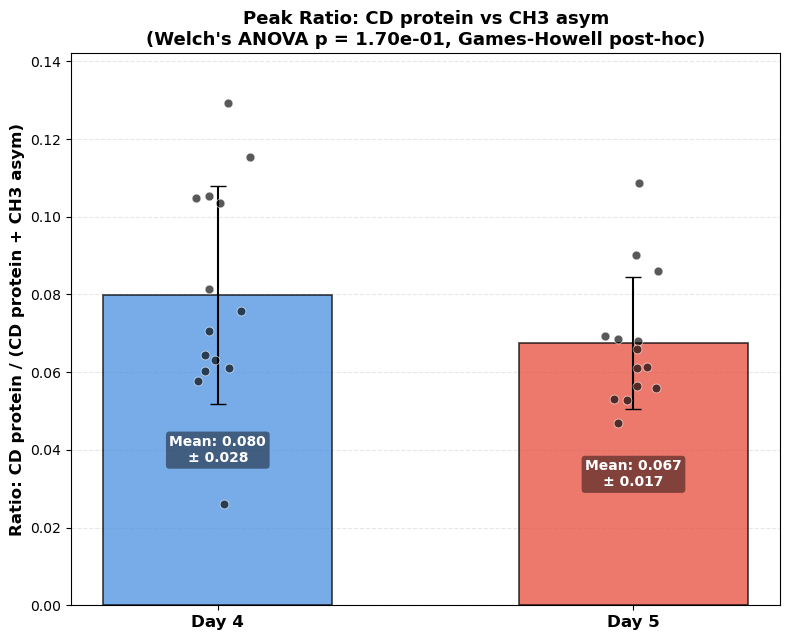

   Condition         Filename     Ratio
0      Day 4  10_day4_001.txt  0.081370
1      Day 4  10_day4_002.txt  0.025975
2      Day 4  10_day4_003.txt  0.057779
3      Day 4  10_day4_004.txt  0.060265
4      Day 4  10_day4_005.txt  0.104708
5      Day 4  10_day4_006.txt  0.105273
6      Day 4  11_day4_001.txt  0.103406
7      Day 4  11_day4_002.txt  0.075684
8      Day 4  11_day4_003.txt  0.115337
9      Day 4  11_day4_004.txt  0.062997
10     Day 4  11_day4_005.txt  0.070553
11     Day 4  11_day4_006.txt  0.064385
12     Day 4  11_day4_007.txt  0.061106
13     Day 4  11_day4_008.txt  0.129183
14     Day 5  14_day5_001.txt  0.090027
15     Day 5  14_day5_002.txt  0.069248
16     Day 5  14_day5_003.txt  0.068604
17     Day 5  14_day5_004.txt  0.086062
18     Day 5  14_day5_005.txt  0.067966
19     Day 5  14_day5_006.txt  0.052985
20     Day 5  14_day5_007.txt  0.056310
21     Day 5  14_day5_008.txt  0.065833
22     Day 5  16_day5_001.txt  0.061198
23     Day 5  16_day5_002.txt  0.055958


In [74]:
cd_ch_peaks = {
    2135: 'CD lipid',
    2185: 'CD protein',
        2850: 'CH2 sym',
    2880: 'CH3 sym',
    2930: 'CH3 asym',
    2960: 'CH2 asym',
    3010: '=C-H'
    
}

ratio_df, ratio_summary, aov_table, posthoc_table = calculate_peak_ratio(
    conditions_data,          # {"Day 4": day4_data, "Day 5": day5_data}
    peak_a='CD protein',         # or 2850
    peak_b='CH3 asym',        # or 2930
    peak_labels=cd_ch_peaks,
    window=5,                 # searches +/- 5 cm^-1 around peak
    plot=True,
        show_ns=False,            # Only display significant comparison brackets (*, **, ***)
    save_path=r"E:\Embryo Day 4 vs Day 5\images\cd_protein_ratio.png"
)

# 3. View individual data points & summary
print(ratio_df[['Condition', 'Filename', 'Ratio']])
print(ratio_summary)

# 4. Save table to CSV
ratio_df.to_csv(r"E:\Embryo Day 4 vs Day 5\images\peak_ratios.csv", index=False)

Loading 24 hr...
Loading 48 hr...
Loading 48 hr LAL...
Saved: E:\24hr vs 48hr\images\Embryo_24hr,_48hr,_48hr_LAL_-_CH_Stretching.png


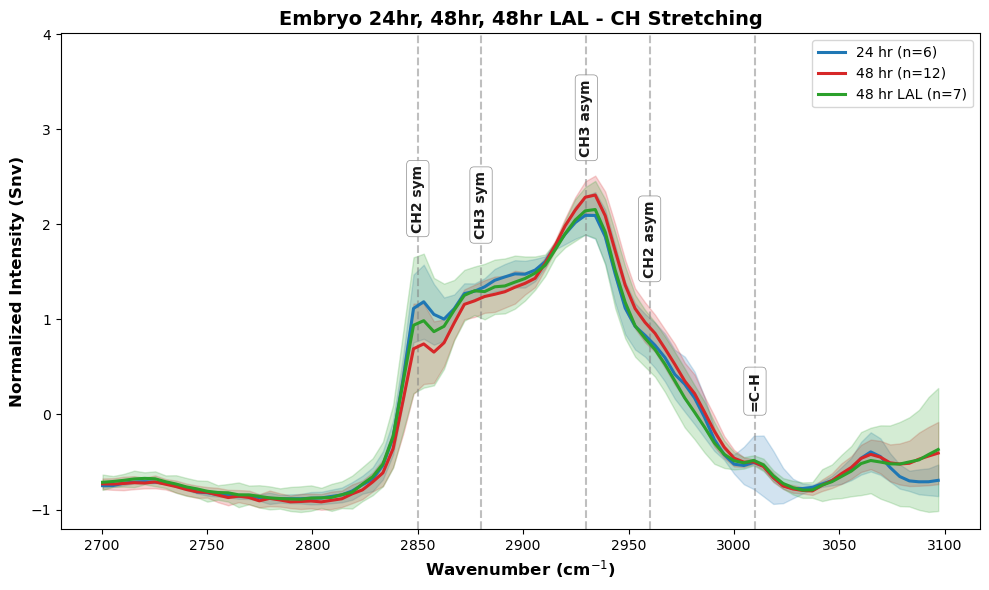

Saved: E:\24hr vs 48hr\images\Embryo_24hr,_48hr,_48hr_LAL_-_Fingerprint.png


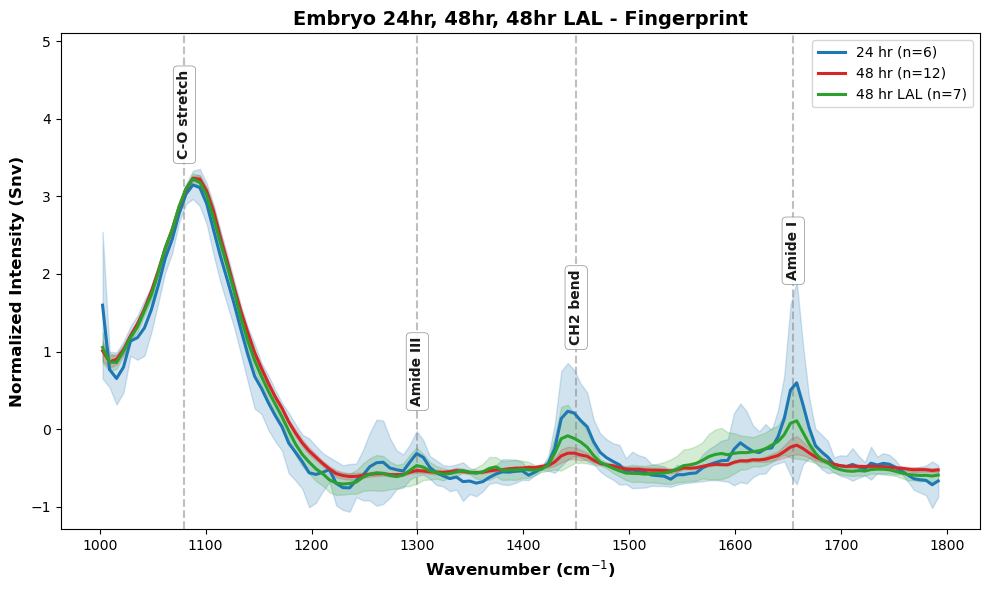

Saved: E:\24hr vs 48hr\images\Embryo_24hr,_48hr,_48hr_LAL_-_CD.png


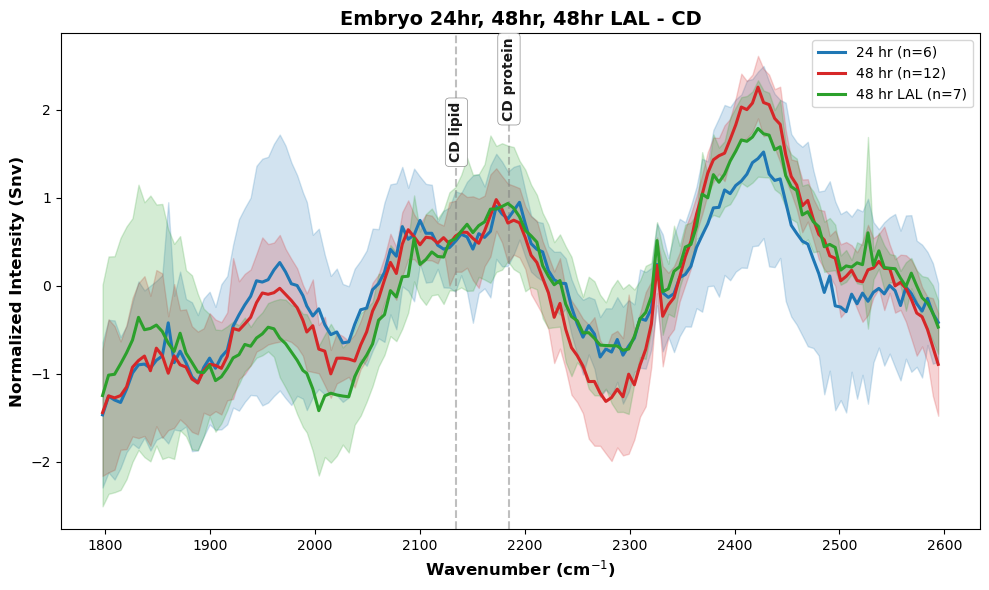

{'wavenumbers': array([1797.66, 1803.38, 1809.1 , 1814.82, 1820.52, 1826.22, 1831.91,
        1837.59, 1843.27, 1848.94, 1854.61, 1860.27, 1865.92, 1871.57,
        1877.2 , 1882.84, 1888.46, 1894.08, 1899.7 , 1905.3 , 1910.9 ,
        1916.5 , 1922.09, 1927.67, 1933.24, 1938.81, 1944.37, 1949.92,
        1955.47, 1961.01, 1966.55, 1972.08, 1977.6 , 1983.12, 1988.63,
        1992.32, 1998.05, 2003.77, 2009.49, 2015.21, 2020.91, 2026.62,
        2032.31, 2038.  , 2043.69, 2049.37, 2055.04, 2060.71, 2066.37,
        2072.03, 2077.68, 2083.33, 2088.97, 2094.6 , 2100.23, 2105.85,
        2111.47, 2117.08, 2122.69, 2128.29, 2133.89, 2139.47, 2145.06,
        2150.64, 2156.21, 2161.78, 2167.34, 2172.89, 2178.44, 2183.99,
        2189.52, 2195.06, 2200.58, 2206.11, 2211.62, 2217.13, 2222.64,
        2228.13, 2233.63, 2239.12, 2244.6 , 2250.08, 2255.55, 2261.02,
        2266.47, 2271.93, 2277.38, 2282.82, 2288.26, 2293.69, 2299.12,
        2304.54, 2309.95, 2315.36, 2320.77, 2326.17, 2331.56, 

In [75]:
conditions_folders = {
    "24 hr": [
        r"E:\Embryo 24hr"
    ],
    "48 hr": [
        r"E:\Embryo 48hr\1",
        r"E:\Embryo 48hr\2",
    ],
    "48 hr LAL": [
        r"E:\Embryo_LAL 48hr\1",
        r"E:\Embryo_LAL 48hr\2"
    ]
}
output_images_dir = r"E:\24hr vs 48hr\images"
os.makedirs(output_images_dir, exist_ok=True)

conditions_data = {}
for cond_name, folder_paths in conditions_folders.items():
    print(f"Loading {cond_name}...")
    conditions_data[cond_name] = load_txt_folder_to_array(folder_paths, baseline_correction=True)

# Choose normalization method: 'minmax' or 'snv'
full_spectrum_normalization = 'snv'  # Change to 'minmax' for min-max normalization

# Define peak labels for different regions
ch_peaks = {
    2850: 'CH2 sym',
    2880: 'CH3 sym', 
    2930: 'CH3 asym',
    2960: 'CH2 asym',
    3010: '=C-H'
}

fingerprint_peaks = {
    1655: 'Amide I',
    1450: 'CH2 bend',
    1300: 'Amide III',
    1080: 'C-O stretch'
}

cd_peaks = {
    2135: 'CD lipid',
    2185: 'CD protein'
}

# Compare conditions in the CH Stretching region
crop_and_normalize_region(
    conditions_data,
    start_wavenumber=2700,
    end_wavenumber=3100,
    region_name="Embryo 24hr, 48hr, 48hr LAL - CH Stretching",
    plot=True,
    peak_labels=ch_peaks,
    normalization='snv',
    show_std=True,          # Shaded +/- 1 SD band
    plot_individual=False,  # Set to True to also show faint individual lines
    save_dir=output_images_dir
)
# Compare conditions in the Fingerprint region
crop_and_normalize_region(
    conditions_data,
    start_wavenumber=1000,
    end_wavenumber=1800,
    region_name="Embryo 24hr, 48hr, 48hr LAL - Fingerprint",
    plot=True,
    peak_labels=fingerprint_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)
# Compare conditions in the Fingerprint region
crop_and_normalize_region(
    conditions_data,
    start_wavenumber=1800,
    end_wavenumber=2600,
    region_name="Embryo 24hr, 48hr, 48hr LAL - CD",
    plot=True,
    peak_labels=cd_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)


Saved: E:\Embryo Day 4 vs Day 5\images\Day_5_CH_Stretching.png


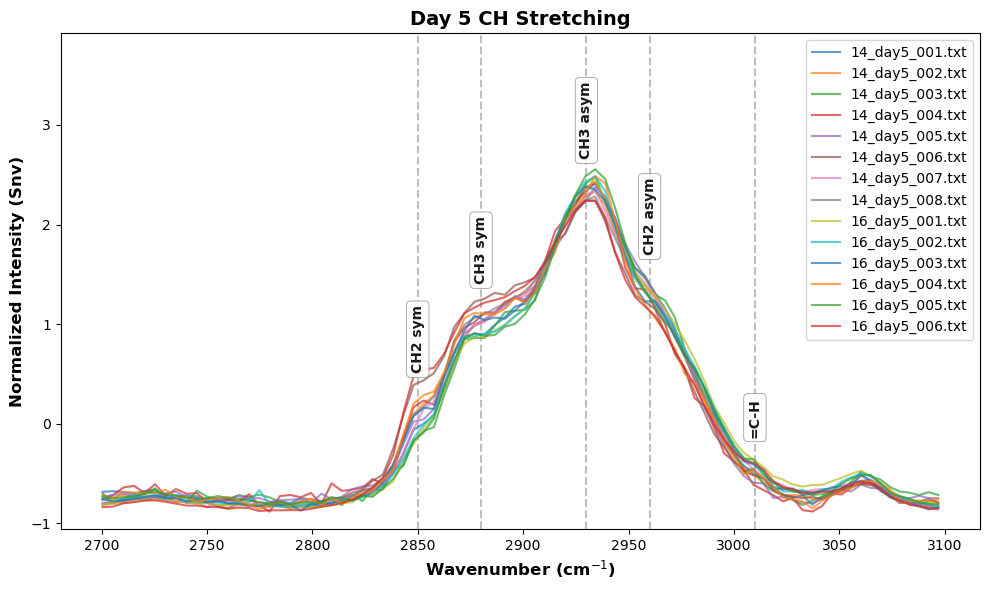

Saved: E:\Embryo Day 4 vs Day 5\images\Day_5_Fingerprint.png


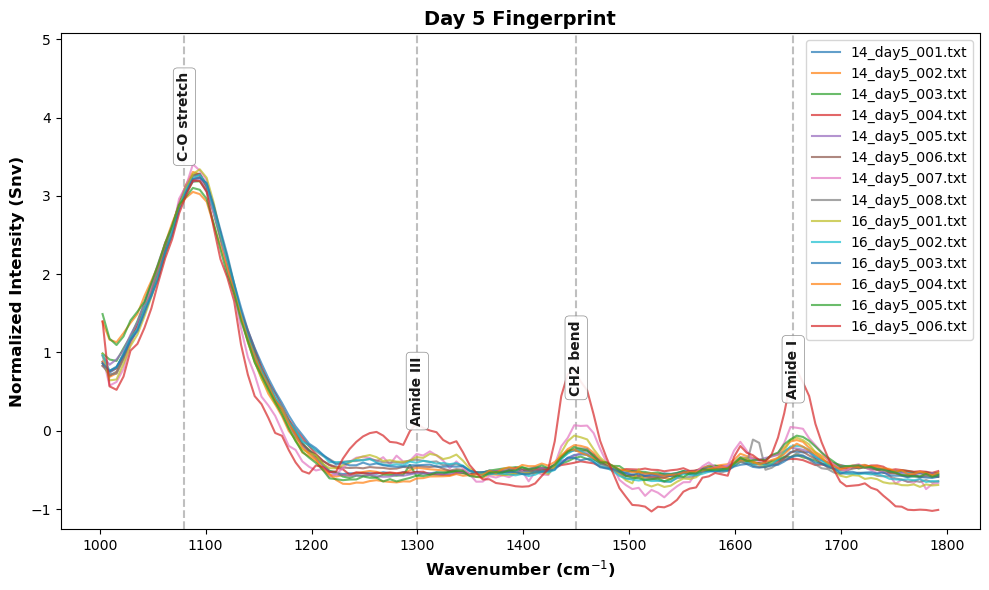

Saved: E:\Embryo Day 4 vs Day 5\images\Day_5_CD.png


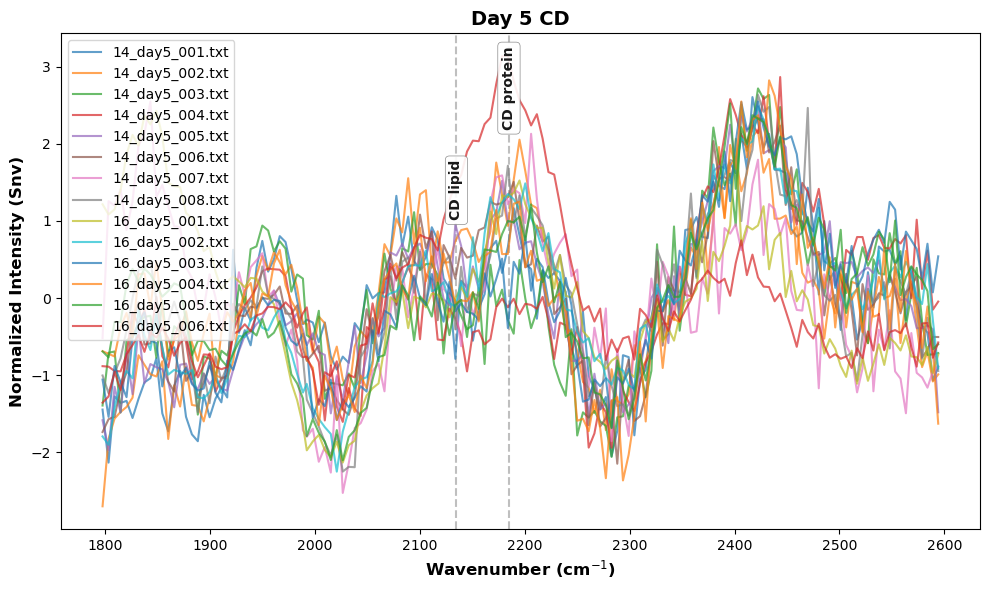

{'wavenumbers': array([1797.66, 1803.38, 1809.1 , 1814.82, 1820.52, 1826.22, 1831.91,
        1837.59, 1843.27, 1848.94, 1854.61, 1860.27, 1865.92, 1871.57,
        1877.2 , 1882.84, 1888.46, 1894.08, 1899.7 , 1905.3 , 1910.9 ,
        1916.5 , 1922.09, 1927.67, 1933.24, 1938.81, 1944.37, 1949.92,
        1955.47, 1961.01, 1966.55, 1972.08, 1977.6 , 1983.12, 1988.63,
        1992.32, 1998.05, 2003.77, 2009.49, 2015.21, 2020.91, 2026.62,
        2032.31, 2038.  , 2043.69, 2049.37, 2055.04, 2060.71, 2066.37,
        2072.03, 2077.68, 2083.33, 2088.97, 2094.6 , 2100.23, 2105.85,
        2111.47, 2117.08, 2122.69, 2128.29, 2133.89, 2139.47, 2145.06,
        2150.64, 2156.21, 2161.78, 2167.34, 2172.89, 2178.44, 2183.99,
        2189.52, 2195.06, 2200.58, 2206.11, 2211.62, 2217.13, 2222.64,
        2228.13, 2233.63, 2239.12, 2244.6 , 2250.08, 2255.55, 2261.02,
        2266.47, 2271.93, 2277.38, 2282.82, 2288.26, 2293.69, 2299.12,
        2304.54, 2309.95, 2315.36, 2320.77, 2326.17, 2331.56, 

In [62]:
crop_and_normalize_region(
    conditions_data['Day 5'],
    start_wavenumber=2700,
    end_wavenumber=3100,
    region_name="Day 5 CH Stretching",
    plot=True,
    peak_labels=ch_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)

# Compare conditions in the Fingerprint region
crop_and_normalize_region(
    conditions_data['Day 5'],
    start_wavenumber=1000,
    end_wavenumber=1800,
    region_name="Day 5 Fingerprint",
    plot=True,
    peak_labels=fingerprint_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)
# Compare conditions in the Fingerprint region
crop_and_normalize_region(
    conditions_data['Day 5'],
    start_wavenumber=1800,
    end_wavenumber=2600,
    region_name="Day 5 CD",
    plot=True,
    peak_labels=cd_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)

Saved: E:\24hr vs 48hr\images\24hr_CH_Stretching.png


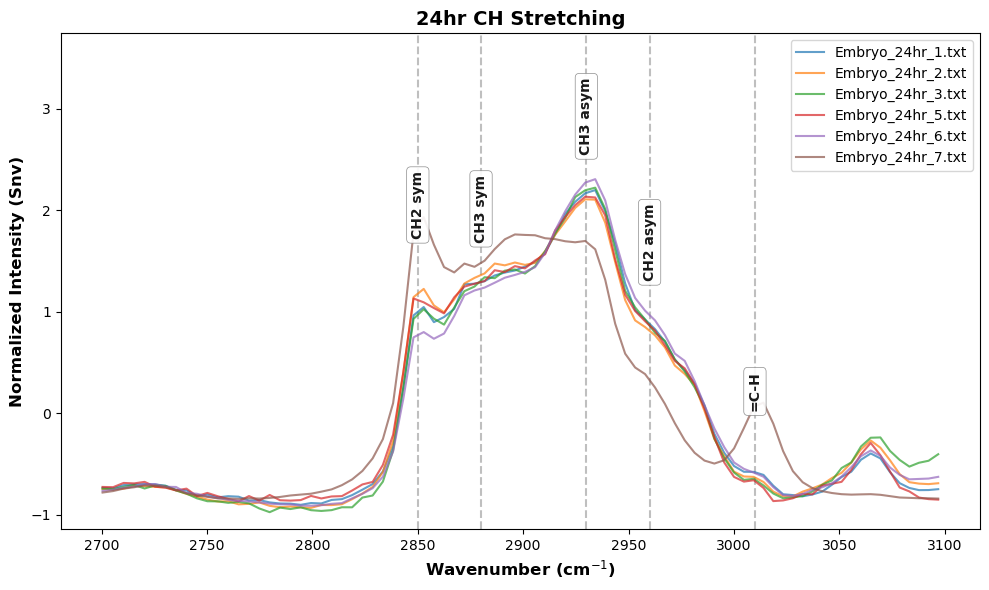

Saved: E:\24hr vs 48hr\images\24hr_Fingerprint.png


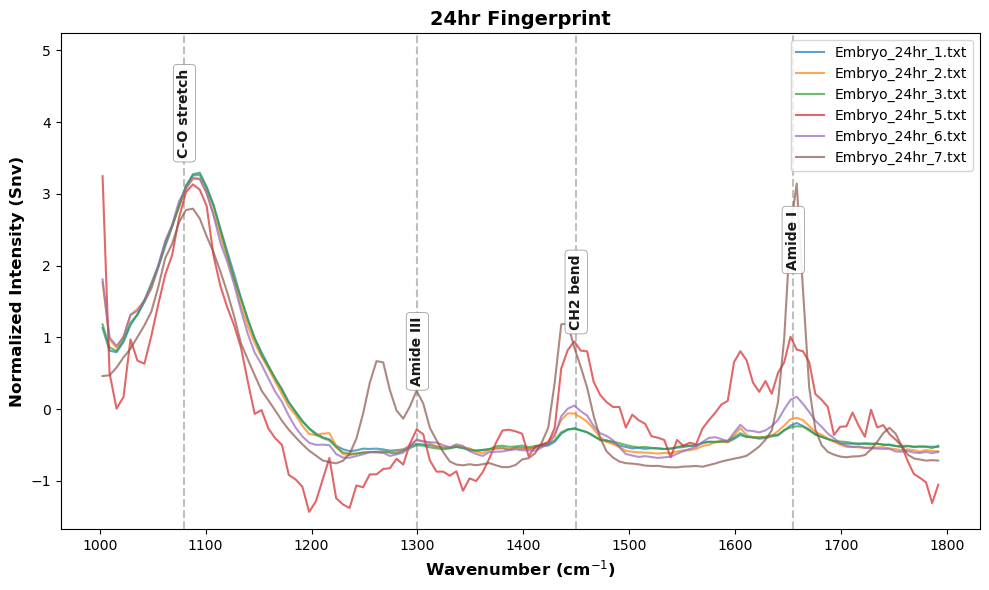

Saved: E:\24hr vs 48hr\images\24hr_CD.png


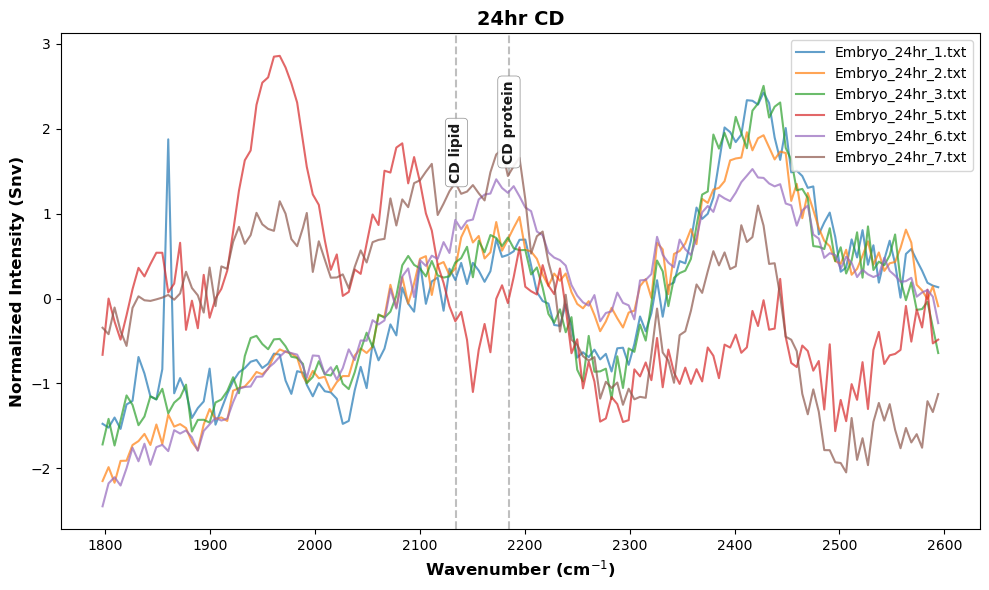

{'wavenumbers': array([1797.66, 1803.38, 1809.1 , 1814.82, 1820.52, 1826.22, 1831.91,
        1837.59, 1843.27, 1848.94, 1854.61, 1860.27, 1865.92, 1871.57,
        1877.2 , 1882.84, 1888.46, 1894.08, 1899.7 , 1905.3 , 1910.9 ,
        1916.5 , 1922.09, 1927.67, 1933.24, 1938.81, 1944.37, 1949.92,
        1955.47, 1961.01, 1966.55, 1972.08, 1977.6 , 1983.12, 1988.63,
        1992.32, 1998.05, 2003.77, 2009.49, 2015.21, 2020.91, 2026.62,
        2032.31, 2038.  , 2043.69, 2049.37, 2055.04, 2060.71, 2066.37,
        2072.03, 2077.68, 2083.33, 2088.97, 2094.6 , 2100.23, 2105.85,
        2111.47, 2117.08, 2122.69, 2128.29, 2133.89, 2139.47, 2145.06,
        2150.64, 2156.21, 2161.78, 2167.34, 2172.89, 2178.44, 2183.99,
        2189.52, 2195.06, 2200.58, 2206.11, 2211.62, 2217.13, 2222.64,
        2228.13, 2233.63, 2239.12, 2244.6 , 2250.08, 2255.55, 2261.02,
        2266.47, 2271.93, 2277.38, 2282.82, 2288.26, 2293.69, 2299.12,
        2304.54, 2309.95, 2315.36, 2320.77, 2326.17, 2331.56, 

In [31]:
# Either the output dict from load_txt_folder_to_array or a 2D numpy array
# day4_data = load_txt_folder_to_array(r"E:\11-07-25 Embryo 10 Day 4")

crop_and_normalize_region(
    conditions_data['24 hr'],
    start_wavenumber=2700,
    end_wavenumber=3100,
    region_name="24hr CH Stretching",
    plot=True,
    peak_labels=ch_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)

# Compare conditions in the Fingerprint region
crop_and_normalize_region(
    conditions_data['24 hr'],
    start_wavenumber=1000,
    end_wavenumber=1800,
    region_name="24hr Fingerprint",
    plot=True,
    peak_labels=fingerprint_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)
# Compare conditions in the Fingerprint region
crop_and_normalize_region(
    conditions_data['24 hr'],
    start_wavenumber=1800,
    end_wavenumber=2600,
    region_name="24hr CD",
    plot=True,
    peak_labels=cd_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)



Saved: E:\24hr vs 48hr\images\48hr_CH_Stretching.png


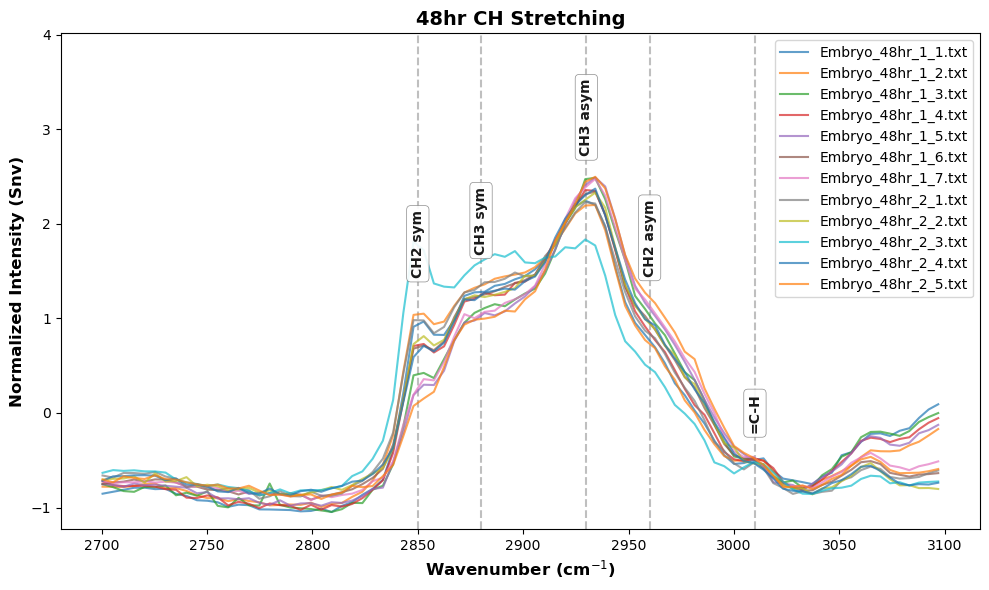

Saved: E:\24hr vs 48hr\images\48hr_Fingerprint.png


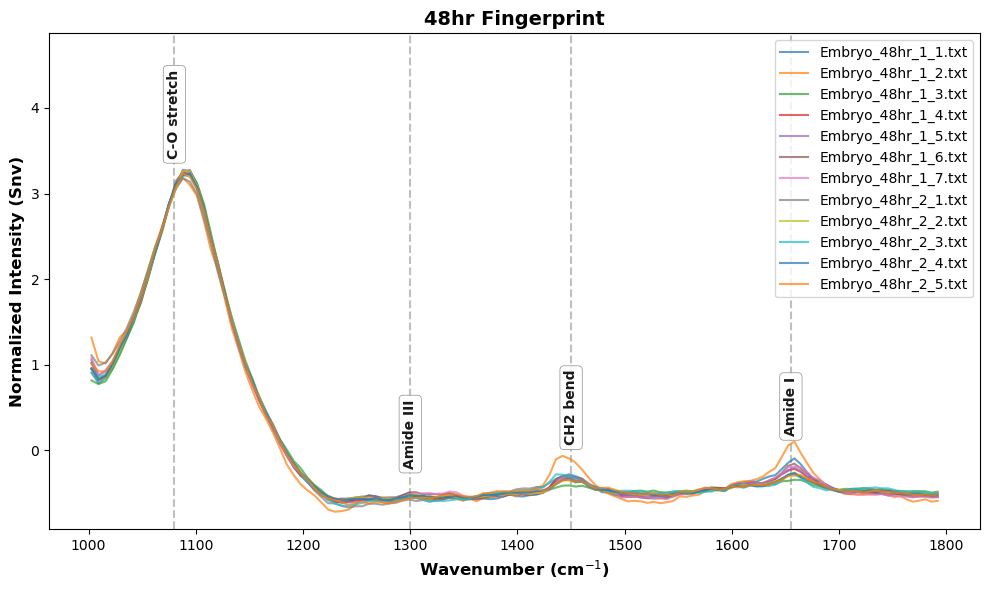

Saved: E:\24hr vs 48hr\images\48hr_CD.png


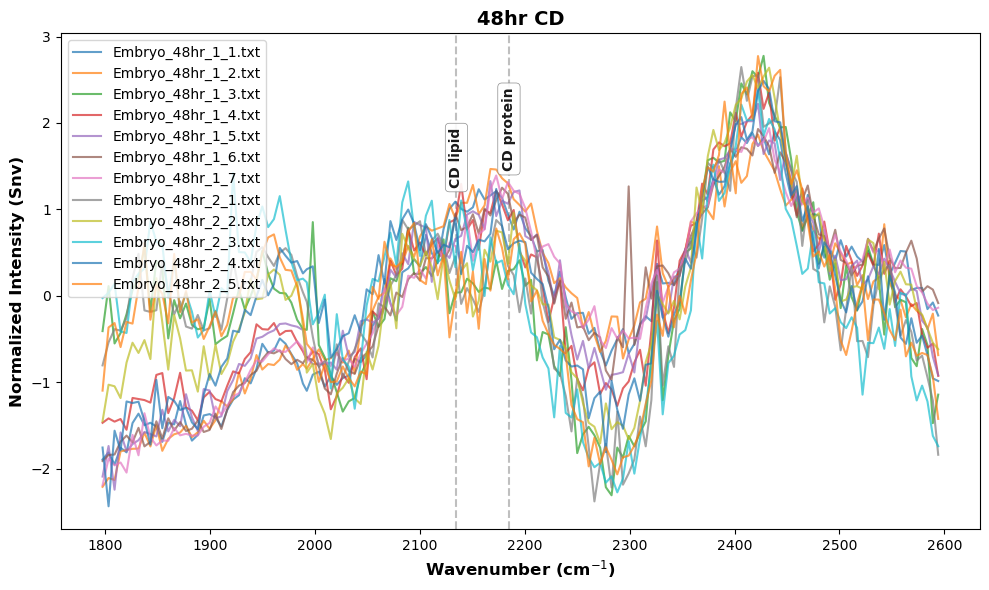

{'wavenumbers': array([1797.66, 1803.38, 1809.1 , 1814.82, 1820.52, 1826.22, 1831.91,
        1837.59, 1843.27, 1848.94, 1854.61, 1860.27, 1865.92, 1871.57,
        1877.2 , 1882.84, 1888.46, 1894.08, 1899.7 , 1905.3 , 1910.9 ,
        1916.5 , 1922.09, 1927.67, 1933.24, 1938.81, 1944.37, 1949.92,
        1955.47, 1961.01, 1966.55, 1972.08, 1977.6 , 1983.12, 1988.63,
        1992.32, 1998.05, 2003.77, 2009.49, 2015.21, 2020.91, 2026.62,
        2032.31, 2038.  , 2043.69, 2049.37, 2055.04, 2060.71, 2066.37,
        2072.03, 2077.68, 2083.33, 2088.97, 2094.6 , 2100.23, 2105.85,
        2111.47, 2117.08, 2122.69, 2128.29, 2133.89, 2139.47, 2145.06,
        2150.64, 2156.21, 2161.78, 2167.34, 2172.89, 2178.44, 2183.99,
        2189.52, 2195.06, 2200.58, 2206.11, 2211.62, 2217.13, 2222.64,
        2228.13, 2233.63, 2239.12, 2244.6 , 2250.08, 2255.55, 2261.02,
        2266.47, 2271.93, 2277.38, 2282.82, 2288.26, 2293.69, 2299.12,
        2304.54, 2309.95, 2315.36, 2320.77, 2326.17, 2331.56, 

In [32]:
crop_and_normalize_region(
    conditions_data['48 hr'],
    start_wavenumber=2700,
    end_wavenumber=3100,
    region_name="48hr CH Stretching",
    plot=True,
    peak_labels=ch_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)

# Compare conditions in the Fingerprint region
crop_and_normalize_region(
    conditions_data['48 hr'],
    start_wavenumber=1000,
    end_wavenumber=1800,
    region_name="48hr Fingerprint",
    plot=True,
    peak_labels=fingerprint_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)
# Compare conditions in the Fingerprint region
crop_and_normalize_region(
    conditions_data['48 hr'],
    start_wavenumber=1800,
    end_wavenumber=2600,
    region_name="48hr CD",
    plot=True,
    peak_labels=cd_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)


Saved: E:\24hr vs 48hr\images\48hr_LAL_CH_Stretching.png


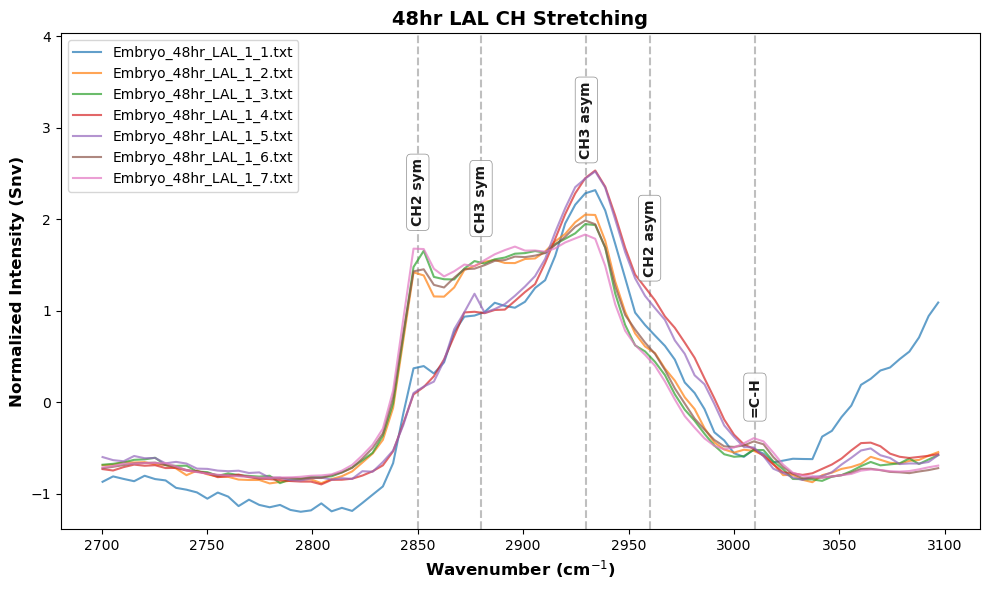

Saved: E:\24hr vs 48hr\images\48hr_LAL_Fingerprint.png


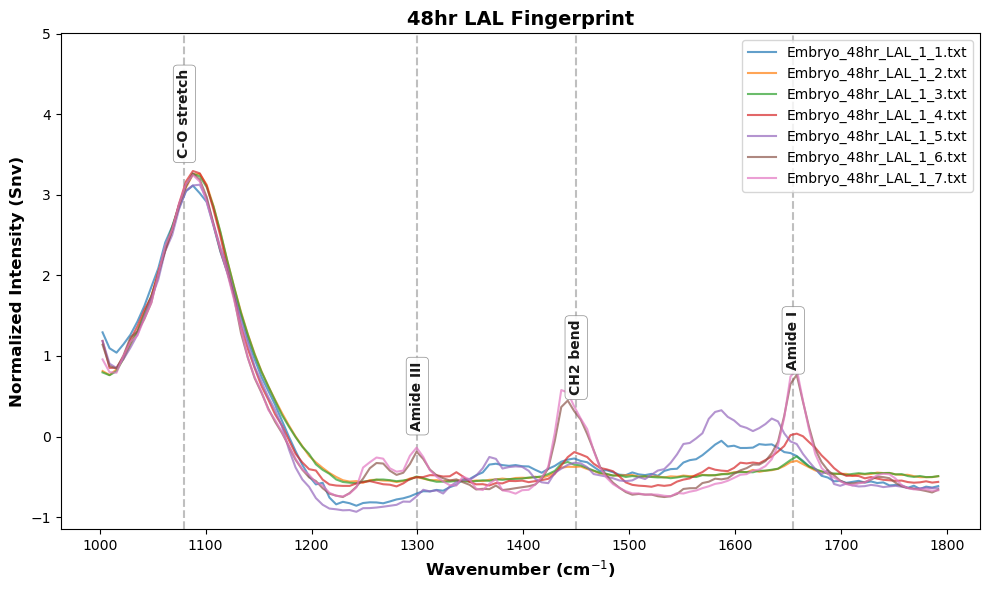

Saved: E:\24hr vs 48hr\images\48hr_LAL_CD.png


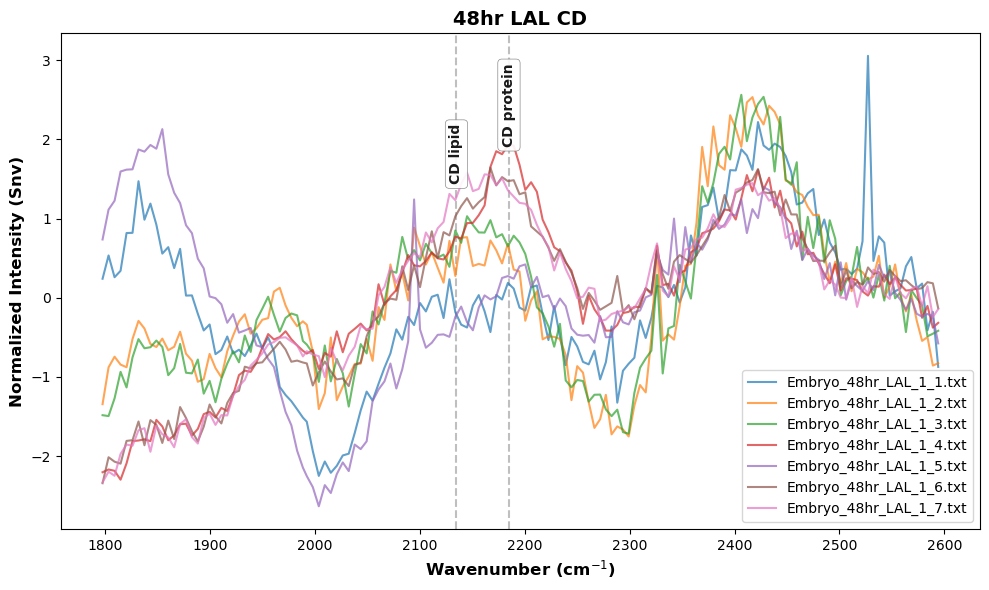

{'wavenumbers': array([1797.66, 1803.38, 1809.1 , 1814.82, 1820.52, 1826.22, 1831.91,
        1837.59, 1843.27, 1848.94, 1854.61, 1860.27, 1865.92, 1871.57,
        1877.2 , 1882.84, 1888.46, 1894.08, 1899.7 , 1905.3 , 1910.9 ,
        1916.5 , 1922.09, 1927.67, 1933.24, 1938.81, 1944.37, 1949.92,
        1955.47, 1961.01, 1966.55, 1972.08, 1977.6 , 1983.12, 1988.63,
        1992.32, 1998.05, 2003.77, 2009.49, 2015.21, 2020.91, 2026.62,
        2032.31, 2038.  , 2043.69, 2049.37, 2055.04, 2060.71, 2066.37,
        2072.03, 2077.68, 2083.33, 2088.97, 2094.6 , 2100.23, 2105.85,
        2111.47, 2117.08, 2122.69, 2128.29, 2133.89, 2139.47, 2145.06,
        2150.64, 2156.21, 2161.78, 2167.34, 2172.89, 2178.44, 2183.99,
        2189.52, 2195.06, 2200.58, 2206.11, 2211.62, 2217.13, 2222.64,
        2228.13, 2233.63, 2239.12, 2244.6 , 2250.08, 2255.55, 2261.02,
        2266.47, 2271.93, 2277.38, 2282.82, 2288.26, 2293.69, 2299.12,
        2304.54, 2309.95, 2315.36, 2320.77, 2326.17, 2331.56, 

In [33]:
crop_and_normalize_region(
    conditions_data['48 hr LAL'],
    start_wavenumber=2700,
    end_wavenumber=3100,
    region_name="48hr LAL CH Stretching",
    plot=True,
    peak_labels=ch_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)

# Compare conditions in the Fingerprint region
crop_and_normalize_region(
    conditions_data['48 hr LAL'],
    start_wavenumber=1000,
    end_wavenumber=1800,
    region_name="48hr LAL Fingerprint",
    plot=True,
    peak_labels=fingerprint_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)
# Compare conditions in the Fingerprint region
crop_and_normalize_region(
    conditions_data['48 hr LAL'],
    start_wavenumber=1800,
    end_wavenumber=2600,
    region_name="48hr LAL CD",
    plot=True,
    peak_labels=cd_peaks,
    normalization='snv',
    show_std=True,
    save_dir=output_images_dir
)


In [66]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pingouin as pg


def get_peak_intensity(wavenumbers, spectrum, peak_wn, window=5):
    """
    Get peak intensity at peak_wn. If window > 0, finds the maximum within peak_wn +/- window.
    """
    if window > 0:
        mask = (wavenumbers >= peak_wn - window) & (wavenumbers <= peak_wn + window)
        if np.any(mask):
            return np.max(spectrum[mask])
    idx = np.argmin(np.abs(wavenumbers - peak_wn))
    return spectrum[idx]


def calculate_peak_ratio(
    data,
    peak_a,
    peak_b,
    peak_labels=None,
    window=5,
    plot=True,
    show_ns=False,
    save_path=None
):
    """
    Calculate Peak A / (Peak A + Peak B) for every spectrum before normalization.
    Performs Welch's ANOVA and Games-Howell post-hoc with pingouin, and plots a
    bar plot with overlapping mean labels, individual data points, and significance bars.

    Parameters:
    -----------
    data : dict or np.ndarray
        Single condition dict, multi-condition dict ({"Day 4": d4, "Day 5": d5}),
        or 2D numpy array [wavenumbers, spectra...].
    peak_a : float or str
        Wavenumber or label for Peak A.
    peak_b : float or str
        Wavenumber or label for Peak B.
    peak_labels : dict, optional
        Dictionary mapping wavenumber values to peak labels (e.g., {2850: 'CH2 sym'}).
    window : float
        Search window in cm^-1 to locate the local peak maximum (default: 5).
    plot : bool
        Whether to generate the bar plot with significance bars.
    show_ns : bool
        Whether to show 'ns' brackets for non-significant comparisons (default: False).
    save_path : str, optional
        File path to save the generated plot.

    Returns:
    --------
    df : pd.DataFrame
        DataFrame with individual spectra ratios and intensities.
    summary : pd.DataFrame
        Summary statistics (Count, Mean, Std, Median) grouped by condition.
    aov : pd.DataFrame
        Welch's ANOVA results table.
    posthoc : pd.DataFrame
        Games-Howell post-hoc pairwise comparison table.
    """
    # 1. Resolve peak labels to numeric wavenumbers
    def resolve_wn(peak, labels):
        if isinstance(peak, (int, float)):
            return float(peak), f"{peak:.0f} cm⁻¹"
        if labels:
            for wn_val, lbl in labels.items():
                if str(lbl).strip().lower() == str(peak).strip().lower():
                    return float(wn_val), str(lbl)
        try:
            return float(peak), f"{float(peak):.0f} cm⁻¹"
        except ValueError:
            raise ValueError(f"Could not resolve peak '{peak}'. Check peak_labels dictionary.")

    wn_a, name_a = resolve_wn(peak_a, peak_labels)
    wn_b, name_b = resolve_wn(peak_b, peak_labels)

    # Detect multi-condition vs single condition
    is_multi_condition = (
        isinstance(data, dict) and
        'wavenumbers' not in data and
        all(isinstance(v, (dict, np.ndarray)) for v in data.values())
    )

    condition_dict = data if is_multi_condition else {"Condition": data}
    records = []

    # 2. Extract un-normalized peak intensities & compute ratios
    for cond_name, cond_val in condition_dict.items():
        if isinstance(cond_val, dict):
            wn = cond_val['wavenumbers']
            spec_mat = cond_val['spectra']  # 2D array before normalization
            fnames = cond_val.get('filenames', [f"Spec_{i+1}" for i in range(spec_mat.shape[1])])
        else:
            wn = cond_val[:, 0]
            spec_mat = cond_val[:, 1:]
            fnames = [f"Spec_{i+1}" for i in range(spec_mat.shape[1])]

        n_samples = spec_mat.shape[1]
        for s_idx in range(n_samples):
            spectrum = spec_mat[:, s_idx]
            int_a = get_peak_intensity(wn, spectrum, wn_a, window=window)
            int_b = get_peak_intensity(wn, spectrum, wn_b, window=window)

            denom = int_a + int_b
            ratio = (int_a / denom) if denom != 0 else np.nan

            records.append({
                'Condition': cond_name,
                'Filename': fnames[s_idx] if s_idx < len(fnames) else f"Spec_{s_idx+1}",
                f'Intensity_{name_a}': int_a,
                f'Intensity_{name_b}': int_b,
                'Ratio': ratio
            })

    df = pd.DataFrame(records)
    conditions = df['Condition'].unique()
    n_cond = len(conditions)

    # 3. Summary statistics
    summary = df.groupby('Condition')['Ratio'].agg(
        Count='count',
        Mean='mean',
        Std='std',
        Median='median'
    ).reindex(conditions).reset_index()

    # 4. Statistical Tests with pingouin
    aov = None
    posthoc = None
    if n_cond >= 2 and len(df.dropna(subset=['Ratio'])) > n_cond:
        try:
            aov = pg.welch_anova(data=df, dv='Ratio', between='Condition')
        except Exception as e:
            print(f"Welch's ANOVA note: {e}")

        try:
            posthoc = pg.pairwise_gameshowell(data=df, dv='Ratio', between='Condition')
        except Exception as e:
            print(f"Games-Howell post-hoc note: {e}")

    # 5. Plotting: Barplot + Mean Text + Jittered Dots + Significance Brackets
    if plot and len(df) > 0:
        fig, ax = plt.subplots(figsize=(8, 6.5))
        palette = ['#4A90E2', '#E74C3C', '#2ECC71', '#9B59B6', '#F39C12', '#1ABC9C']

        x_positions = np.arange(n_cond)
        means = summary['Mean'].values
        stds = summary['Std'].fillna(0).values

        # Bar plot
        bars = ax.bar(
            x_positions,
            means,
            yerr=stds,
            capsize=6,
            color=[palette[i % len(palette)] for i in range(n_cond)],
            alpha=0.75,
            edgecolor='black',
            linewidth=1.2,
            width=0.55,
            zorder=2
        )

        # Overlay individual points and mean text label
        for idx, cond in enumerate(conditions):
            vals = df[df['Condition'] == cond]['Ratio'].dropna().values
            jitter = np.random.normal(0, 0.035, size=len(vals))

            # Individual sample points
            ax.scatter(
                x_positions[idx] + jitter,
                vals,
                color='black',
                alpha=0.65,
                s=40,
                edgecolors='white',
                linewidths=0.6,
                zorder=3
            )

            # Mean text label positioned in the center of the bar
            mean_val = means[idx]
            std_val = stds[idx]
            label_y = mean_val * 0.5
            ax.text(
                x_positions[idx],
                label_y,
                f"Mean: {mean_val:.3f}\n± {std_val:.3f}",
                ha='center',
                va='center',
                fontsize=10,
                fontweight='bold',
                color='white',
                bbox=dict(boxstyle='round,pad=0.25', facecolor='black', alpha=0.45, edgecolor='none'),
                zorder=4
            )

        # Significance Brackets (Games-Howell)
        max_data_val = max(df['Ratio'].max(), np.max(means + stds))
        y_range = max_data_val - min(0, df['Ratio'].min())
        step = 0.09 * y_range
        tick_h = 0.02 * y_range
        current_y = max_data_val + 0.06 * y_range

        if posthoc is not None and len(posthoc) > 0:
            cond_to_x = {c: x for x, c in zip(x_positions, conditions)}
            comps = posthoc.copy()
            if not show_ns:
                comps = comps[comps['pval'] < 0.05]

            for _, row in comps.iterrows():
                x1 = cond_to_x[row['A']]
                x2 = cond_to_x[row['B']]
                if x1 > x2:
                    x1, x2 = x2, x1

                p = row['pval']
                if p < 0.001:
                    stars = '***'
                elif p < 0.01:
                    stars = '**'
                elif p < 0.05:
                    stars = '*'
                else:
                    stars = 'ns'

                # Draw horizontal bracket with vertical ticks
                ax.plot([x1, x1, x2, x2],
                        [current_y - tick_h, current_y, current_y, current_y - tick_h],
                        color='black', lw=1.3, zorder=5)

                # Annotation text
                ax.text(
                    (x1 + x2) / 2,
                    current_y + 0.005 * y_range,
                    stars,
                    ha='center',
                    va='bottom',
                    fontsize=12,
                    fontweight='bold',
                    color='black',
                    zorder=5
                )
                current_y += step

        # Axes labels & Title
        ax.set_xticks(x_positions)
        ax.set_xticklabels(conditions, fontsize=12, fontweight='bold')
        ax.set_ylabel(f"Ratio: {name_a} / ({name_a} + {name_b})", fontsize=12, fontweight='bold')

        title_str = f"Peak Ratio: {name_a} vs {name_b}"
        if aov is not None and not aov.empty:
            p_col = 'p_unc' if 'p_unc' in aov.columns else 'p-unc'
            p_val = aov[p_col].values[0]
            title_str += f"\n(Welch's ANOVA p = {p_val:.2e}, Games-Howell post-hoc)"
        ax.set_title(title_str, fontsize=13, fontweight='bold')

        ax.set_ylim(bottom=0, top=current_y + 0.04 * y_range)
        ax.grid(True, axis='y', linestyle='--', alpha=0.3)
        plt.tight_layout()

        if save_path:
            os.makedirs(os.path.dirname(os.path.abspath(save_path)), exist_ok=True)
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
            print(f"Saved ratio plot: {save_path}")

        plt.show()

    return df, summary, aov, posthoc



Saved ratio plot: E:\24hr vs 48hr\images\lip_pro_ratio.png


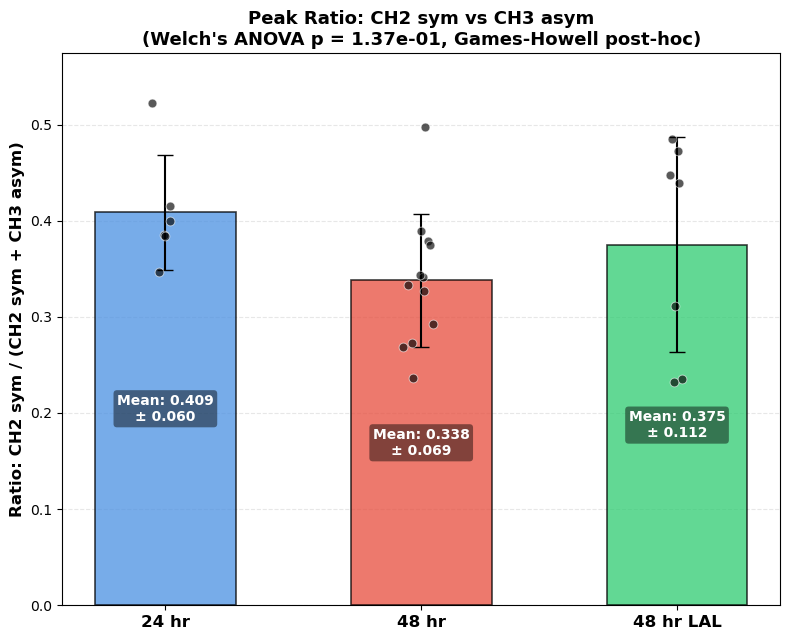

    Condition                 Filename     Ratio
0       24 hr        Embryo_24hr_1.txt  0.385427
1       24 hr        Embryo_24hr_2.txt  0.414841
2       24 hr        Embryo_24hr_3.txt  0.384216
3       24 hr        Embryo_24hr_5.txt  0.399562
4       24 hr        Embryo_24hr_6.txt  0.346796
5       24 hr        Embryo_24hr_7.txt  0.522092
6       48 hr      Embryo_48hr_1_1.txt  0.379075
7       48 hr      Embryo_48hr_1_2.txt  0.389670
8       48 hr      Embryo_48hr_1_3.txt  0.292570
9       48 hr      Embryo_48hr_1_4.txt  0.340980
10      48 hr      Embryo_48hr_1_5.txt  0.268605
11      48 hr      Embryo_48hr_1_6.txt  0.332812
12      48 hr      Embryo_48hr_1_7.txt  0.272550
13      48 hr      Embryo_48hr_2_1.txt  0.375227
14      48 hr      Embryo_48hr_2_2.txt  0.344048
15      48 hr      Embryo_48hr_2_3.txt  0.497901
16      48 hr      Embryo_48hr_2_4.txt  0.326939
17      48 hr      Embryo_48hr_2_5.txt  0.236282
18  48 hr LAL  Embryo_48hr_LAL_1_1.txt  0.310922
19  48 hr LAL  Embry

In [77]:
# 1. Define peak labels
ch_peaks = {
    2850: 'CH2 sym',
    2880: 'CH3 sym',
    2930: 'CH3 asym',
    2960: 'CH2 asym',
    3010: '=C-H'
}

# 2. Compute ratio: e.g. CH2 / (CH2 + CH3) using either wavenumbers or labels
ratio_df, ratio_summary, aov_table, posthoc_table = calculate_peak_ratio(
    conditions_data,          # {"Day 4": day4_data, "Day 5": day5_data}
    peak_a='CH2 sym',         # or 2850
    peak_b='CH3 asym',        # or 2930
    peak_labels=ch_peaks,
    window=5,                 # searches +/- 5 cm^-1 around peak
    plot=True,
    save_path=r"E:\24hr vs 48hr\images\lip_pro_ratio.png"
)

# 3. View individual data points & summary
print(ratio_df[['Condition', 'Filename', 'Ratio']])
print(ratio_summary)

# 4. Save table to CSV
ratio_df.to_csv(r"E:\24hr vs 48hr\images\peak_ratios.csv", index=False)


Saved ratio plot: E:\24hr vs 48hr\images\unsat_ratio.png


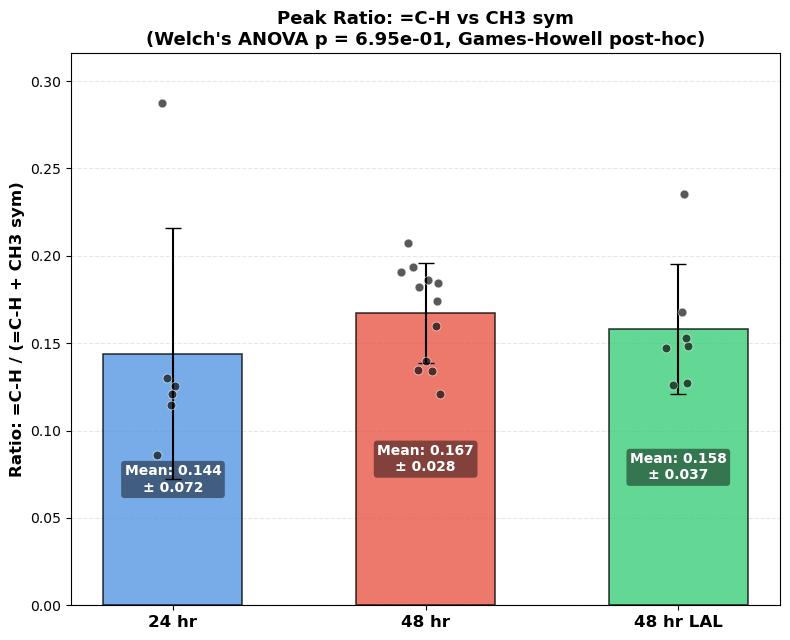

    Condition                 Filename     Ratio
0       24 hr        Embryo_24hr_1.txt  0.125297
1       24 hr        Embryo_24hr_2.txt  0.114576
2       24 hr        Embryo_24hr_3.txt  0.120709
3       24 hr        Embryo_24hr_5.txt  0.085981
4       24 hr        Embryo_24hr_6.txt  0.130060
5       24 hr        Embryo_24hr_7.txt  0.287235
6       48 hr      Embryo_48hr_1_1.txt  0.193613
7       48 hr      Embryo_48hr_1_2.txt  0.173834
8       48 hr      Embryo_48hr_1_3.txt  0.207357
9       48 hr      Embryo_48hr_1_4.txt  0.190511
10      48 hr      Embryo_48hr_1_5.txt  0.186047
11      48 hr      Embryo_48hr_1_6.txt  0.159984
12      48 hr      Embryo_48hr_1_7.txt  0.184158
13      48 hr      Embryo_48hr_2_1.txt  0.140021
14      48 hr      Embryo_48hr_2_2.txt  0.134602
15      48 hr      Embryo_48hr_2_3.txt  0.120809
16      48 hr      Embryo_48hr_2_4.txt  0.133875
17      48 hr      Embryo_48hr_2_5.txt  0.181931
18  48 hr LAL  Embryo_48hr_LAL_1_1.txt  0.235609
19  48 hr LAL  Embry

In [81]:
# 2. Compute ratio: e.g. CH2 / (CH2 + CH3) using either wavenumbers or labels
ratio_df, ratio_summary, aov_table, posthoc_table = calculate_peak_ratio(
    conditions_data,          # {"Day 4": day4_data, "Day 5": day5_data}
    peak_a='=C-H',         # or 2850
    peak_b='CH3 sym',        # or 2930
    peak_labels=ch_peaks,
    window=5,                 # searches +/- 5 cm^-1 around peak
    plot=True,
    save_path=r"E:\24hr vs 48hr\images\unsat_ratio.png"
)

# 3. View individual data points & summary
print(ratio_df[['Condition', 'Filename', 'Ratio']])
print(ratio_summary)

# 4. Save table to CSV
ratio_df.to_csv(r"E:\24hr vs 48hr\images\peak_ratios.csv", index=False)
# Statistical tables:
print("Welch's ANOVA Table:")
print(aov_table)
print("\nGames-Howell Post-hoc Comparisons:")
print(posthoc_table[['A', 'B', 'diff', 'pval']])

Saved ratio plot: E:\24hr vs 48hr\images\CD_protein_ratio.png


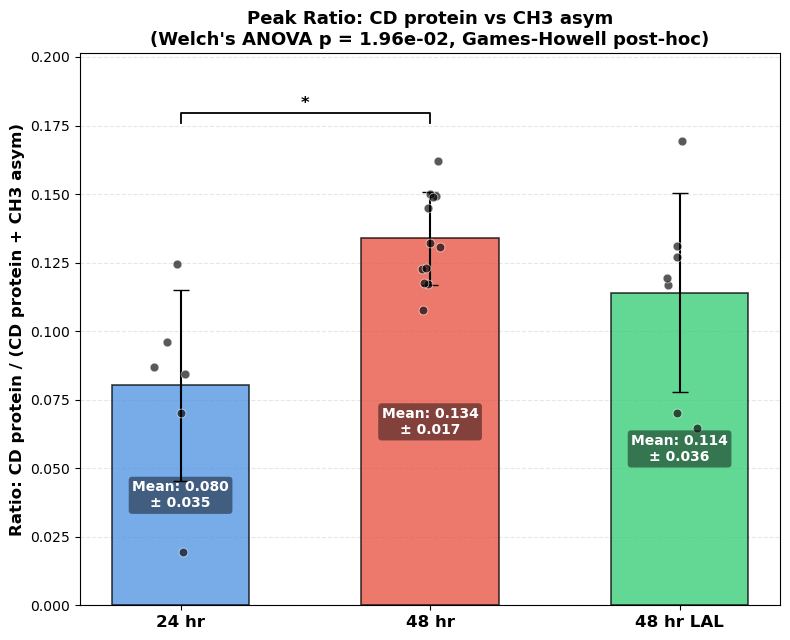

    Condition                 Filename     Ratio
0       24 hr        Embryo_24hr_1.txt  0.084407
1       24 hr        Embryo_24hr_2.txt  0.087000
2       24 hr        Embryo_24hr_3.txt  0.124337
3       24 hr        Embryo_24hr_5.txt  0.070028
4       24 hr        Embryo_24hr_6.txt  0.096195
5       24 hr        Embryo_24hr_7.txt  0.019360
6       48 hr      Embryo_48hr_1_1.txt  0.130526
7       48 hr      Embryo_48hr_1_2.txt  0.122513
8       48 hr      Embryo_48hr_1_3.txt  0.161912
9       48 hr      Embryo_48hr_1_4.txt  0.149395
10      48 hr      Embryo_48hr_1_5.txt  0.149987
11      48 hr      Embryo_48hr_1_6.txt  0.107585
12      48 hr      Embryo_48hr_1_7.txt  0.117170
13      48 hr      Embryo_48hr_2_1.txt  0.148954
14      48 hr      Embryo_48hr_2_2.txt  0.117563
15      48 hr      Embryo_48hr_2_3.txt  0.144993
16      48 hr      Embryo_48hr_2_4.txt  0.122886
17      48 hr      Embryo_48hr_2_5.txt  0.132308
18  48 hr LAL  Embryo_48hr_LAL_1_1.txt  0.169249
19  48 hr LAL  Embry

In [82]:
ratio_df, ratio_summary, aov_table, posthoc_table = calculate_peak_ratio(
    conditions_data,          # {"Day 4": day4_data, "Day 5": day5_data}
    peak_a='CD protein',         # or 2850
    peak_b='CH3 asym',        # or 2930
    peak_labels=cd_ch_peaks,
    window=5,                 # searches +/- 5 cm^-1 around peak
    plot=True,
    save_path=r"E:\24hr vs 48hr\images\CD_protein_ratio.png"
)

# 3. View individual data points & summary
print(ratio_df[['Condition', 'Filename', 'Ratio']])
print(ratio_summary)

# 4. Save table to CSV
ratio_df.to_csv(r"E:\24hr vs 48hr\images\peak_ratios.csv", index=False)
# Statistical tables:
print("Welch's ANOVA Table:")
print(aov_table)
print("\nGames-Howell Post-hoc Comparisons:")
print(posthoc_table[['A', 'B', 'diff', 'pval']])

Saved ratio plot: E:\24hr vs 48hr\images\CD_lipid_ratio.png


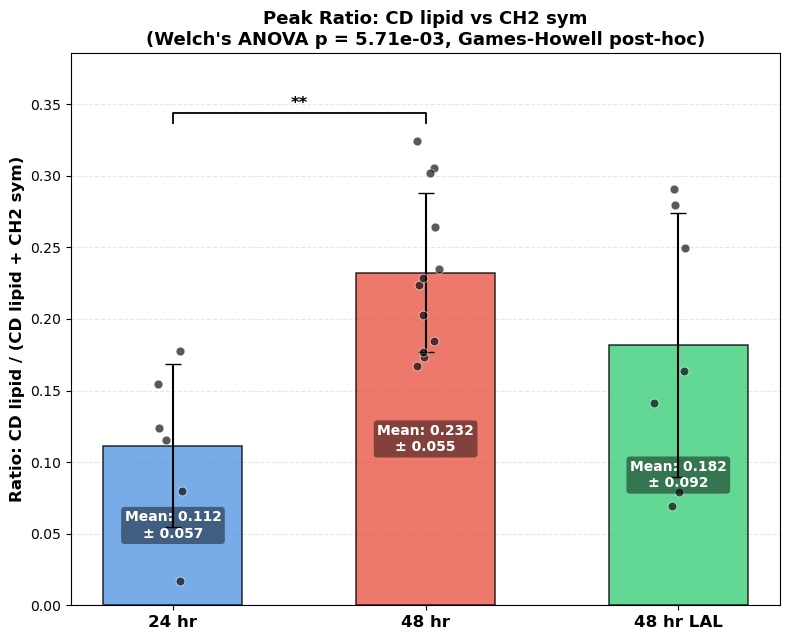

    Condition                 Filename     Ratio
0       24 hr        Embryo_24hr_1.txt  0.123840
1       24 hr        Embryo_24hr_2.txt  0.115490
2       24 hr        Embryo_24hr_3.txt  0.177959
3       24 hr        Embryo_24hr_5.txt  0.080175
4       24 hr        Embryo_24hr_6.txt  0.154655
5       24 hr        Embryo_24hr_7.txt  0.017076
6       48 hr      Embryo_48hr_1_1.txt  0.202990
7       48 hr      Embryo_48hr_1_2.txt  0.173259
8       48 hr      Embryo_48hr_1_3.txt  0.305656
9       48 hr      Embryo_48hr_1_4.txt  0.264120
10      48 hr      Embryo_48hr_1_5.txt  0.301686
11      48 hr      Embryo_48hr_1_6.txt  0.184897
12      48 hr      Embryo_48hr_1_7.txt  0.224015
13      48 hr      Embryo_48hr_2_1.txt  0.228726
14      48 hr      Embryo_48hr_2_2.txt  0.176994
15      48 hr      Embryo_48hr_2_3.txt  0.166864
16      48 hr      Embryo_48hr_2_4.txt  0.235108
17      48 hr      Embryo_48hr_2_5.txt  0.324131
18  48 hr LAL  Embryo_48hr_LAL_1_1.txt  0.290714
19  48 hr LAL  Embry

In [83]:
ratio_df, ratio_summary, aov_table, posthoc_table = calculate_peak_ratio(
    conditions_data,          # {"Day 4": day4_data, "Day 5": day5_data}
    peak_a='CD lipid',         # or 2850
    peak_b='CH2 sym',        # or 2930
    peak_labels=cd_ch_peaks,
    window=5,                 # searches +/- 5 cm^-1 around peak
    plot=True,
    save_path=r"E:\24hr vs 48hr\images\CD_lipid_ratio.png"
)

# 3. View individual data points & summary
print(ratio_df[['Condition', 'Filename', 'Ratio']])
print(ratio_summary)

# 4. Save table to CSV
ratio_df.to_csv(r"E:\24hr vs 48hr\images\peak_ratios.csv", index=False)
# Statistical tables:
print("Welch's ANOVA Table:")
print(aov_table)
print("\nGames-Howell Post-hoc Comparisons:")
print(posthoc_table[['A', 'B', 'diff', 'pval']])